# Baseline model: small-case experiment
Three cities and ten equiprobable joint demand scenarios with synthetic inputs.

1. Compare the MILP optimum with independent exhaustive enumeration.
2. Check edge cases.
3. Analyze parameter sensitivity.

The objective combines initial entry cost, annual vehicle cost, expected idle penalties, and expected unmet demand losses. Entry y and fleet allocation q are common across scenarios; O and U are scenario-specific.

Solver: [SciPy milp / HiGHS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).


In [1]:
                                    
try:
    from scipy.optimize import milp
    import pandas
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy", "pandas", "scipy>=1.9"])

# 1. MILP solution and independent exhaustive verification

## 1-1. Setup

In [2]:
'Verification on a synthetic instance with three cities and ten scenarios.'
from itertools import product
from fractions import Fraction
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint

def show(title, table):
    print('\n' + title)
    try:
        from IPython import get_ipython
        from IPython.display import display
        if get_ipython() is not None:
            display(table)
            return
    except ImportError:
        pass
    print(table.to_string(index=False))

## 1-2. City inputs and units

In [3]:
                                                  
cities = ['A', 'B', 'C']
M = np.array([80., 100., 120.])
kappa = np.array([10., 10., 10.])
qbar = np.array([2, 2, 2])
F = np.array([20., 20., 20.])
K = np.array([5., 5., 5.])
c_plus = np.array([0., 0., 0.])
c_minus = np.array([10., 10., 10.])
Q = 4

input_table = pd.DataFrame({
    'Input': ['M_c', 'kappa_c', 'qbar_c', 'F_c', 'K_c', 'c_plus', 'c_minus'],
    'Unit': ['trips/year', 'trips/vehicle/year', 'vehicles', 'USD/entry', 'USD/vehicle/year',
             'USD/unused capacity trip', 'USD/unmet trip'],
    **{name: [a[i] for a in [M, kappa, qbar, F, K, c_plus, c_minus]]
       for i, name in enumerate(cities)},})
show('Input table', input_table)


Input table


,Input,Unit,A,B,C
0,M_c,trips/year,80.0,100.0,120.0
1,kappa_c,trips/vehicle/year,10.0,10.0,10.0
2,qbar_c,vehicles,2.0,2.0,2.0
3,F_c,USD/entry,20.0,20.0,20.0
4,K_c,USD/vehicle/year,5.0,5.0,5.0
5,c_plus,USD/unused capacity trip,0.0,0.0,0.0
6,c_minus,USD/unmet trip,10.0,10.0,10.0


## 1-3. Common settings and ten joint scenarios

In [4]:
                                         
p = np.array([
    [.05, .05, .05], [.20, .20, .20], [.50, .50, .50], [.80, .80, .80],
    [.05, .20, .50], [.20, .50, .05], [.50, .05, .20],
    [.20, .50, .80], [.50, .80, .20], [.80, .20, .50]])
S, C = p.shape
probability = np.full(S, 1 / S)                         
D = p * M[None, :]                                       

common_table = pd.DataFrame([
    ('Candidate cities', ', '.join(cities)), ('Scenario count', str(S)),
    ('Scenario probability', f'Each 1/{S}'), ('Fleet limit Q', str(Q)),
    ('Fleet comparison levels', '0, 4, 8 vehicles'),
    ('Choice probability levels', ', '.join(map(str, np.unique(p)))),
    ('Evaluation period', 'Entry and allocation chosen once; one year of operation'),
    ('Common decisions', 'Same y_c and q_c in every scenario'),
    ('Scenario-specific variables', 'O_c^s, U_c^s'),
    ('Computation scope', 'Baseline MILP and independent exhaustive enumeration')], columns=['Item', 'Setting'])
show('Common settings', common_table)
scenario_table = pd.DataFrame({'Scenario': np.arange(1, S + 1), 'Occurrence probability': probability})
for i, name in enumerate(cities):
    scenario_table[f'p_{name}'] = p[:, i]
for i, name in enumerate(cities):
    scenario_table[f'D_{name} (trips/year)'] = D[:, i]
show('Choice probabilities and demand scenarios', scenario_table)

                                          
assert C == len(cities) and np.isfinite(p).all() and ((0 <= p) & (p <= 1)).all()
assert isinstance(Q, (int, np.integer)) and Q >= 0
assert np.isclose(probability.sum(), 1)
for a in [M, kappa, qbar, F, K, c_plus, c_minus]:
    assert a.shape == (C,) and np.isfinite(a).all() and (a >= 0).all()
assert np.equal(qbar, np.floor(qbar)).all()
qbar = qbar.astype(int)


Common settings

Choice probabilities and demand scenarios


,Item,Setting
0,Candidate cities,"A, B, C"
1,Scenario count,10
2,Scenario probability,Each 1/10
3,Fleet limit Q,4
4,Fleet comparison levels,"0, 4, 8 vehicles"
5,Choice probability levels,"0.05, 0.2, 0.5, 0.8"
6,Evaluation period,Entry and allocation chosen once; one year of ...
7,Common decisions,Same y_c and q_c in every scenario
8,Scenario-specific variables,"O_c^s, U_c^s"
9,Computation scope,Baseline MILP and independent exhaustive enume...


,Scenario,Occurrence probability,p_A,p_B,p_C,D_A (trips/year),D_B (trips/year),D_C (trips/year)
0,1,0.1,0.05,0.05,0.05,4.0,5.0,6.0
1,2,0.1,0.20,0.20,0.20,16.0,20.0,24.0
2,3,0.1,0.50,0.50,0.50,40.0,50.0,60.0
3,4,0.1,0.80,0.80,0.80,64.0,80.0,96.0
4,5,0.1,0.05,0.20,0.50,4.0,20.0,60.0
5,6,0.1,0.20,0.50,0.05,16.0,50.0,6.0
6,7,0.1,0.50,0.05,0.20,40.0,5.0,24.0
7,8,0.1,0.20,0.50,0.80,16.0,50.0,96.0
8,9,0.1,0.50,0.80,0.20,40.0,80.0,24.0
9,10,0.1,0.80,0.20,0.50,64.0,20.0,60.0


## 1-4. Objective and constraints

In [5]:
                                            
iy = np.arange(C)
iq = np.arange(C, 2 * C)
iO = np.arange(2 * C, 2 * C + S * C).reshape(S, C)
iU = np.arange(2 * C + S * C, 2 * C + 2 * S * C).reshape(S, C)
nvars = 2 * C + 2 * S * C
objective = np.zeros(nvars)
objective[iy], objective[iq] = F, K
objective[iO] = probability[:, None] * c_plus
objective[iU] = probability[:, None] * c_minus

                                                                                        
lower = np.zeros(nvars)
upper = np.full(nvars, np.inf)
upper[iy], upper[iq] = 1, qbar
integrality = np.zeros(nvars, dtype=int)
integrality[iy] = integrality[iq] = 1

rows, lbs, ubs = [], [], []
def add_constraint(coefficients, lb, ub):
    row = np.zeros(nvars)
    for index, value in coefficients.items():
        row[index] = value
    rows.append(row)
    lbs.append(lb)
    ubs.append(ub)

for c in range(C):
                                                  
    add_constraint({iq[c]: 1, iy[c]: -qbar[c]}, -np.inf, 0)
add_constraint({idx: 1 for idx in iq}, -np.inf, Q)
for s in range(S):
    for c in range(C):
                                                       
        add_constraint({iq[c]: kappa[c], iO[s, c]: -1, iU[s, c]: 1}, D[s, c], D[s, c])

result = milp(c=objective, integrality=integrality,
              bounds=Bounds(lower, upper),
              constraints=LinearConstraint(np.array(rows), np.array(lbs), np.array(ubs)),
              options={'mip_rel_gap': 0.0, 'time_limit': 60})
if result.status != 0:
    raise RuntimeError(f'Optimal solution check failed: status={result.status}, {result.message}')
x = result.x
y, q = np.rint(x[iy]).astype(int), np.rint(x[iq]).astype(int)
O_solver, U_solver = x[iO], x[iU]
capacity = kappa * q

## 1-5. Optimal allocation and cost breakdown

In [6]:
show('Optimal entry and allocation by city', pd.DataFrame({
    'City': cities, 'Entry y': y, 'Vehicles q': q,
    'Annual capacity': capacity, 'Mean demand': probability @ D,
    'Expected unused capacity': probability @ O_solver,
    'Expected unmet demand': probability @ U_solver}))

entry_cost = float(F @ y)
vehicle_cost = float(K @ q)
over_cost = float(np.sum(probability[:, None] * c_plus * O_solver))
under_cost = float(np.sum(probability[:, None] * c_minus * U_solver))
recalculated = entry_cost + vehicle_cost + over_cost + under_cost
show('Objective cost breakdown (USD)', pd.DataFrame({
    'Item': ['Initial entry cost', 'Fixed vehicle cost', 'Expected idle penalty', 'Expected unmet demand loss', 'Total'],
    'USD': [entry_cost, vehicle_cost, over_cost, under_cost, recalculated]}))
details = []
for s in range(S):
    for c, name in enumerate(cities):
        details.append([s + 1, name, D[s, c], capacity[c], O_solver[s, c], U_solver[s, c]])
show('Demand, capacity, and losses by scenario (trips/year)', pd.DataFrame(
    details, columns=['Scenario', 'City', 'Demand D', 'Capacity', 'Unused capacity O', 'Unmet demand U']))



served = np.minimum(D, capacity[None, :])
unmet = np.maximum(D - capacity[None, :], 0)
unused = np.maximum(capacity[None, :] - D, 0)

scenario_summary = pd.DataFrame({
    'Scenario': np.arange(1, S + 1).astype(str),
    'Total demand': D.sum(axis=1),
    'Served demand': served.sum(axis=1),
    'Unmet demand': unmet.sum(axis=1),
    'Unused capacity': unused.sum(axis=1),
})

columns = ['Total demand', 'Served demand', 'Unmet demand', 'Unused capacity']

                                           
totals = scenario_summary[columns].sum()
averages = totals / S

scenario_summary = pd.concat([
    scenario_summary,
    pd.DataFrame([
        {'Scenario': 'Total', **totals.to_dict()},
        {'Scenario': f"Mean: sum / {S}", **averages.to_dict()},
    ]),
], ignore_index=True)

show(
    'Total demand, service, unmet demand, and unused capacity by scenario',
    scenario_summary.round(2),
)

print('Values are trip counts, not dollar amounts.')
print('The sum combines alternative scenarios for calculation; it is not annual total demand.')
print(
    f"Mean demand {averages['Total demand']:.1f} trips"
    f" = mean served demand {averages['Served demand']:.1f} trips"
    f" + mean unmet demand {averages['Unmet demand']:.1f} trips"
)
print(
    f"Fleet capacity {capacity.sum():.1f} trips"
    f" = mean served demand {averages['Served demand']:.1f} trips"
    f" + mean unused capacity {averages['Unused capacity']:.1f} trips"
)


Optimal entry and allocation by city

Objective cost breakdown (USD)

Demand, capacity, and losses by scenario (trips/year)

Total demand, service, unmet demand, and unused capacity by scenario
Values are trip counts, not dollar amounts.
The sum combines alternative scenarios for calculation; it is not annual total demand.
Mean demand 114.0 trips = mean served demand 34.2 trips + mean unmet demand 79.8 trips
Fleet capacity 40.0 trips = mean served demand 34.2 trips + mean unused capacity 5.8 trips


,City,Entry y,Vehicles q,Annual capacity,Mean demand,Expected unused capacity,Expected unmet demand
0,A,0,0,0.0,30.4,0.0,30.4
1,B,1,2,20.0,38.0,3.0,21.0
2,C,1,2,20.0,45.6,2.8,28.4


,Item,USD
0,Initial entry cost,40.0
1,Fixed vehicle cost,20.0
2,Expected idle penalty,0.0
3,Expected unmet demand loss,798.0
4,Total,858.0


,Scenario,City,Demand D,Capacity,Unused capacity O,Unmet demand U
0,1,A,4.0,0.0,0.0,4.0
1,1,B,5.0,20.0,15.0,0.0
2,1,C,6.0,20.0,14.0,0.0
3,2,A,16.0,0.0,0.0,16.0
4,2,B,20.0,20.0,0.0,0.0
5,2,C,24.0,20.0,0.0,4.0
6,3,A,40.0,0.0,0.0,40.0
7,3,B,50.0,20.0,0.0,30.0
8,3,C,60.0,20.0,0.0,40.0
9,4,A,64.0,0.0,0.0,64.0


,Scenario,Total demand,Served demand,Unmet demand,Unused capacity
0,1,15.0,11.0,4.0,29.0
1,2,60.0,40.0,20.0,0.0
2,3,150.0,40.0,110.0,0.0
3,4,240.0,40.0,200.0,0.0
4,5,84.0,40.0,44.0,0.0
5,6,72.0,26.0,46.0,14.0
6,7,69.0,25.0,44.0,15.0
7,8,162.0,40.0,122.0,0.0
8,9,144.0,40.0,104.0,0.0
9,10,144.0,40.0,104.0,0.0


## 1-6. Allocation economics
Compare q=(1,1,2) with q=(0,2,2). Entering the third city adds 8 in contribution margin and 20 in entry cost. Both allocations use four vehicles, so vehicle cost is unchanged. The three-city objective is 870, which is 12 higher than the two-city objective.

Compare (1,1,2), (1,2,1), and (2,1,1) to examine the tendency to prioritize larger markets under these otherwise identical city conditions.


In [7]:
from itertools import product

                
                                                             
 
                                         
                                 
                              
                                       
                            

comparison_rows = []

                                
allocations = product(
    *[range(int(limit) + 1) for limit in qbar]
)

                    
mean_total_demand = float((probability @ D).sum())
no_entry_loss = float(c_minus @ (probability @ D))

for allocation in allocations:

    q_compare = np.array(allocation, dtype=int)

                           
    if q_compare.sum() > Q:
        continue

    y_compare = (q_compare > 0).astype(int)
    capacity_compare = kappa * q_compare

                         
    served_compare = np.minimum(D, capacity_compare[None, :])
    unmet_compare = np.maximum(D - capacity_compare[None, :], 0)
    unused_compare = np.maximum(capacity_compare[None, :] - D, 0)

                              
    mean_served = probability @ served_compare
    mean_unmet = probability @ unmet_compare
    mean_unused = probability @ unused_compare

    total_served = float(mean_served.sum())
    total_unmet = float(mean_unmet.sum())
    total_unused = float(mean_unused.sum())
    total_capacity = float(capacity_compare.sum())

                            
    service_rate = (
        100 * total_served / mean_total_demand
        if mean_total_demand > 0 else np.nan
    )

                              
    utilization = (
        100 * total_served / total_capacity
        if total_capacity > 0 else np.nan
    )

                        
    entry = float(F @ y_compare)
    vehicle = float(K @ q_compare)
    idle_penalty = float(c_plus @ mean_unused)
    unmet_loss = float(c_minus @ mean_unmet)
    served_margin = float(c_minus @ mean_served)

    objective = entry + vehicle + idle_penalty + unmet_loss

    label = "[" + ",".join(map(str, allocation)) + "]"

    comparison_rows.append({
        'Allocation': label,
        'Number of entered cities': int(y_compare.sum()),
        'Total vehicles': int(q_compare.sum()),
        'A mean served demand': float(mean_served[0]),
        'B mean served demand': float(mean_served[1]),
        'C mean served demand': float(mean_served[2]),
        'Total mean served demand': total_served,
        'Total mean unmet demand': total_unmet,
        'Total mean unused capacity': total_unused,
        'Service rate (%)': service_rate,
        'Utilization (%)': utilization,
        'Service contribution margin': served_margin,
        'Entry cost': entry,
        'Vehicle cost': vehicle,
        'Idle penalty': idle_penalty,
        'Unmet demand loss': unmet_loss,
        'Objective': objective,
        'Improvement over no entry': no_entry_loss - objective,
    })

comparison = pd.DataFrame(comparison_rows).set_index('Allocation')

                      
baseline_label = "[0,2,2]"

if baseline_label in comparison.index:
    baseline = comparison.loc[baseline_label].copy()

    comparison['Increase in served demand from baseline'] = (
        comparison['Total mean served demand'] - baseline['Total mean served demand']
    )
    comparison['Increase in contribution margin from baseline'] = (
        comparison['Service contribution margin'] - baseline['Service contribution margin']
    )
    comparison['Increase in entry cost from baseline'] = (
        comparison['Entry cost'] - baseline['Entry cost']
    )
    comparison['Increase in vehicle cost from baseline'] = (
        comparison['Vehicle cost'] - baseline['Vehicle cost']
    )
    comparison['Increase in idle penalty from baseline'] = (
        comparison['Idle penalty'] - baseline['Idle penalty']
    )
    comparison['Increase in objective from baseline'] = (
        comparison['Objective'] - baseline['Objective']
    )

                     
comparison = comparison.sort_values(
    ['Objective', 'Total vehicles'],
    kind="stable",
)

                    
best_objective = comparison['Objective'].min()

comparison.insert(
    0,
    'Optimal status',
    np.where(
        np.isclose(
            comparison['Objective'],
            best_objective,
            rtol=0,
            atol=1e-7,
        ),
        'Optimal',
        "",
    ),
)

          
                                 
def show_comparison(title, columns):
    table = comparison[columns].round(2).reset_index()
    show(title, table.fillna("—"))


show_comparison(
    'Service comparison across allocations (trips)',
    [
        'Optimal status',
        'Total vehicles',
        'Number of entered cities',
        'A mean served demand',
        'B mean served demand',
        'C mean served demand',
        'Total mean served demand',
        'Total mean unmet demand',
        'Total mean unused capacity',
    ],
)

show_comparison(
    'Service and utilization rates across allocations',
    [
        'Optimal status',
        'Total vehicles',
        'Service rate (%)',
        'Utilization (%)',
    ],
)

show_comparison(
    'Contribution and cost comparison (USD)',
    [
        'Optimal status',
        'Service contribution margin',
        'Entry cost',
        'Vehicle cost',
        'Idle penalty',
        'Unmet demand loss',
        'Objective',
        'Improvement over no entry',
    ],
)

if baseline_label in comparison.index:
    show_comparison(
        'Differences from [0,2,2]: service in trips, costs in USD',
        [
            'Increase in served demand from baseline',
            'Increase in contribution margin from baseline',
            'Increase in entry cost from baseline',
            'Increase in vehicle cost from baseline',
            'Increase in idle penalty from baseline',
            'Increase in objective from baseline',
        ],
    )

best_allocations = comparison.index[
    comparison['Optimal status'] == 'Optimal'
].tolist()

print(f"Allocations compared: {len(comparison)}")
print(f"Optimal allocations: {', '.join(best_allocations)}")
print(f"Minimum objective: {best_objective:,.2f} USD")
print('Means are weighted by scenario probabilities.')
print('Objective = entry cost + vehicle cost + idle penalty + unmet demand loss')
print('Improvement over no entry = no-entry loss - allocation objective')


Service comparison across allocations (trips)

Service and utilization rates across allocations

Contribution and cost comparison (USD)

Differences from [0,2,2]: service in trips, costs in USD
Allocations compared: 23
Optimal allocations: [0,2,2]
Minimum objective: 858.00 USD
Means are weighted by scenario probabilities.
Objective = entry cost + vehicle cost + idle penalty + unmet demand loss
Improvement over no entry = no-entry loss - allocation objective


,Allocation,Optimal status,Total vehicles,Number of entered cities,A mean served demand,B mean served demand,C mean served demand,Total mean served demand,Total mean unmet demand,Total mean unused capacity
0,"[0,2,2]",Optimal,4,2,0.0,17.0,17.2,34.2,79.8,5.8
1,"[1,1,2]",,4,3,8.8,9.0,17.2,35.0,79.0,5.0
2,"[1,2,1]",,4,3,8.8,17.0,9.2,35.0,79.0,5.0
3,"[2,0,2]",,4,2,15.6,0.0,17.2,32.8,81.2,7.2
4,"[2,2,0]",,4,2,15.6,17.0,0.0,32.6,81.4,7.4
5,"[2,1,1]",,4,3,15.6,9.0,9.2,33.8,80.2,6.2
6,"[0,1,2]",,3,2,0.0,9.0,17.2,26.2,87.8,3.8
7,"[0,2,1]",,3,2,0.0,17.0,9.2,26.2,87.8,3.8
8,"[1,0,2]",,3,2,8.8,0.0,17.2,26.0,88.0,4.0
9,"[1,2,0]",,3,2,8.8,17.0,0.0,25.8,88.2,4.2


,Allocation,Optimal status,Total vehicles,Service rate (%),Utilization (%)
0,"[0,2,2]",Optimal,4,30.00,85.5
1,"[1,1,2]",,4,30.70,87.5
2,"[1,2,1]",,4,30.70,87.5
3,"[2,0,2]",,4,28.77,82.0
4,"[2,2,0]",,4,28.60,81.5
5,"[2,1,1]",,4,29.65,84.5
6,"[0,1,2]",,3,22.98,87.33
7,"[0,2,1]",,3,22.98,87.33
8,"[1,0,2]",,3,22.81,86.67
9,"[1,2,0]",,3,22.63,86.0


,Allocation,Optimal status,Service contribution margin,Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,Improvement over no entry
0,"[0,2,2]",Optimal,342.0,40.0,20.0,0.0,798.0,858.0,282.0
1,"[1,1,2]",,350.0,60.0,20.0,0.0,790.0,870.0,270.0
2,"[1,2,1]",,350.0,60.0,20.0,0.0,790.0,870.0,270.0
3,"[2,0,2]",,328.0,40.0,20.0,0.0,812.0,872.0,268.0
4,"[2,2,0]",,326.0,40.0,20.0,0.0,814.0,874.0,266.0
5,"[2,1,1]",,338.0,60.0,20.0,0.0,802.0,882.0,258.0
6,"[0,1,2]",,262.0,40.0,15.0,0.0,878.0,933.0,207.0
7,"[0,2,1]",,262.0,40.0,15.0,0.0,878.0,933.0,207.0
8,"[1,0,2]",,260.0,40.0,15.0,0.0,880.0,935.0,205.0
9,"[1,2,0]",,258.0,40.0,15.0,0.0,882.0,937.0,203.0


,Allocation,Increase in served demand from baseline,Increase in contribution margin from baseline,Increase in entry cost from baseline,Increase in vehicle cost from baseline,Increase in idle penalty from baseline,Increase in objective from baseline
0,"[0,2,2]",0.0,0.0,0.0,0.0,0.0,0.0
1,"[1,1,2]",0.8,8.0,20.0,0.0,0.0,12.0
2,"[1,2,1]",0.8,8.0,20.0,0.0,0.0,12.0
3,"[2,0,2]",-1.4,-14.0,0.0,0.0,0.0,14.0
4,"[2,2,0]",-1.6,-16.0,0.0,0.0,0.0,16.0
5,"[2,1,1]",-0.4,-4.0,20.0,0.0,0.0,24.0
6,"[0,1,2]",-8.0,-80.0,0.0,-5.0,0.0,75.0
7,"[0,2,1]",-8.0,-80.0,0.0,-5.0,0.0,75.0
8,"[1,0,2]",-8.2,-82.0,0.0,-5.0,0.0,77.0
9,"[1,2,0]",-8.4,-84.0,0.0,-5.0,0.0,79.0


## 1-7. Independent enumeration of feasible (y,q) pairs

In [8]:
                                                    
def frac(value):
    return Fraction(str(float(value)))

enumerated = []
for yy in product([0, 1], repeat=C):
    for qq in product(*(range(qbar[c] * yy[c] + 1) for c in range(C))):
        if sum(qq) > Q:
            continue
        cost = sum(frac(F[c]) * yy[c] + frac(K[c]) * qq[c] for c in range(C))
        for s in range(S):
            for c in range(C):
                demand = frac(M[c]) * frac(p[s, c])
                balance = frac(kappa[c]) * qq[c] - demand
                cost += (frac(c_plus[c]) * max(balance, 0)
                         + frac(c_minus[c]) * max(-balance, 0)) / S
        enumerated.append((cost, yy, qq))
enumerated.sort()
oracle_cost = enumerated[0][0]
oracle_solutions = [(yy, qq) for cost, yy, qq in enumerated if cost == oracle_cost]
show('All optimal solutions from exhaustive enumeration', pd.DataFrame([
    {'y': yy, 'q': qq, 'Objective (USD)': float(oracle_cost)} for yy, qq in oracle_solutions]))
show('Top 10 exhaustive candidates', pd.DataFrame([
    {'y': yy, 'q': qq, 'Objective (USD)': float(cost)} for cost, yy, qq in enumerated[:10]]))


All optimal solutions from exhaustive enumeration

Top 10 exhaustive candidates


,y,q,Objective (USD)
0,"(0, 1, 1)","(0, 2, 2)",858.0


,y,q,Objective (USD)
0,"(0, 1, 1)","(0, 2, 2)",858.0
1,"(1, 1, 1)","(1, 1, 2)",870.0
2,"(1, 1, 1)","(1, 2, 1)",870.0
3,"(1, 0, 1)","(2, 0, 2)",872.0
4,"(1, 1, 0)","(2, 2, 0)",874.0
5,"(1, 1, 1)","(0, 2, 2)",878.0
6,"(1, 1, 1)","(2, 1, 1)",882.0
7,"(1, 1, 1)","(2, 0, 2)",892.0
8,"(1, 1, 1)","(2, 2, 0)",894.0
9,"(0, 1, 1)","(0, 1, 2)",933.0


## 1-8. Feasibility and agreement with the independent optimum

In [9]:
tol = 1e-7
checks = {
    'Solver optimal termination': result.status == 0,
    'y/q integrality and domains': np.all(np.abs(x[iy] - y) <= tol)
        and np.all(np.abs(x[iq] - q) <= tol) and np.all((y >= 0) & (y <= 1)) and np.all(q >= 0),
    'Entry-allocation linkage': bool(np.all(q <= qbar * y)),
    'Total fleet limit': bool(q.sum() <= Q),
    'O/U nonnegativity': bool(np.all(O_solver >= -tol) and np.all(U_solver >= -tol)),
    'Balance in every scenario': bool(np.allclose(capacity - D, O_solver - U_solver, atol=tol, rtol=0)),
    'Objective recalculation': bool(np.isclose(result.fun, recalculated, atol=tol, rtol=0)),
    'Exhaustive objective agreement': bool(np.isclose(result.fun, float(oracle_cost), atol=tol, rtol=0)),
    'Membership in exhaustive optimal solution set': (tuple(y), tuple(q)) in oracle_solutions,
}
                                               
active = c_plus + c_minus > 0
checks['O/U agreement with positive loss coefficients'] = bool(
    np.allclose(O_solver[:, active], np.maximum(capacity - D, 0)[:, active], atol=tol, rtol=0)
    and np.allclose(U_solver[:, active], np.maximum(D - capacity, 0)[:, active], atol=tol, rtol=0))
show('Validation results', pd.DataFrame({'Check': list(checks),
    'Result': ['PASS' if value else 'FAIL' for value in checks.values()]}))
assert all(checks.values()), 'Validation failed; inspect the failed checks.'
print(f'Validation complete: enumerated {len(enumerated)} (y,q) pairs; optimal solutions {len(oracle_solutions)}')
print(f'Optimal objective = {result.fun:.6f} USD | MIP gap = {result.mip_gap}')
print('These checks establish implementation consistency for the synthetic baseline instance.')


Validation results
Validation complete: enumerated 60 (y,q) pairs; optimal solutions 1
Optimal objective = 858.000000 USD | MIP gap = 0.0
These checks establish implementation consistency for the synthetic baseline instance.


,Check,Result
0,Solver optimal termination,PASS
1,y/q integrality and domains,PASS
2,Entry-allocation linkage,PASS
3,Total fleet limit,PASS
4,O/U nonnegativity,PASS
5,Balance in every scenario,PASS
6,Objective recalculation,PASS
7,Exhaustive objective agreement,PASS
8,Membership in exhaustive optimal solution set,PASS
9,O/U agreement with positive loss coefficients,PASS


## 1-9. Baseline results
The optimal allocation is **q=(0,2,2)** with **y=(0,1,1)** and an objective of **USD 858.00**. Independent enumeration of all 60 feasible (y,q) pairs gives the same result.

Concentrating in B and C is preferable to entering all three cities because of entry costs and the value of additional scenario-specific service. The objective is 40 in entry cost + 20 in vehicle cost + 798 in expected unmet demand loss. The idle penalty is zero.


# 2. Edge-case checks

## 2-1. Plotting and display utilities

In [10]:
import importlib.util
import subprocess
import sys

required = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy>=1.9',
            'matplotlib': 'matplotlib', 'IPython': 'ipython'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

from copy import deepcopy
from itertools import product
from fractions import Fraction
from pathlib import Path
import html
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML

fonts = {f.name for f in font_manager.fontManager.ttflist}
korean_font = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic',
                               'Noto Sans CJK KR'] if f in fonts), None)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.unicode_minus': False, 'figure.dpi': 115,
                     'savefig.dpi': 160, 'axes.titleweight': 'bold'})
def sa_L(ko, en):
    return en

CITY_COLORS = ['#2563A6', '#C98A21', '#39796B']
COST_COLORS = ['#2563A6', '#C98A21', '#8A6C9F', '#C9CDD3']
sa_FIGURES = []
def sa_showfig(fig, name):
    'Display a figure in the cell output.'
    sa_FIGURES.append((name, fig))
    display(fig)
    plt.close(fig)

def sa_note(text):
    display(Markdown(text))

def sa_detail(title, table):
    'Expandable table of exact results.'
    display(HTML('<details><summary style="cursor:pointer;padding:10px;color:#2563A6">'
                 + html.escape(title) + '</summary>'
                 + table.to_html(index=False, float_format=lambda x: f'{x:,.4f}')
                 + '</details>'))

def sa_cards(items):
    boxes = ''.join('<div style="flex:1;min-width:140px;padding:14px;background:#f2f5f8;'
                    'border-left:4px solid #2563A6"><div style="font-size:13px">'
                    + html.escape(str(k)) + '</div><strong style="font-size:24px">'
                    + html.escape(str(v)) + '</strong></div>' for k, v in items)
    display(HTML('<div style="display:flex;flex-wrap:wrap;gap:10px;margin:12px 0">'
                 + boxes + '</div>'))
# Snapshot baseline inputs before running independent experiments.
sa_BASE = {key: np.asarray(globals()[key]).copy()
           for key in ['M', 'kappa', 'qbar', 'F', 'K', 'c_plus', 'c_minus', 'p']}
sa_BASE['Q'] = int(Q)
sa_component_labels = ['Entry cost', 'Vehicle cost', 'Idle penalty', 'Unmet demand loss']


## Optimization and independent reference functions
Compare the MILP with exhaustive enumeration using the same objective and constraints.

In [11]:
sa_TOL = 1e-7
sa_SOLVE_LOG = []

def sa_validate(data):
    n = len(data['M'])
    for key in ['M','kappa','qbar','F','K','c_plus','c_minus']:
        a = np.asarray(data[key])
        assert a.shape == (n,) and np.isfinite(a).all() and (a >= 0).all(), key
    assert np.all(data['qbar'] == np.floor(data['qbar']))
    assert isinstance(data['Q'], (int, np.integer)) and data['Q'] >= 0
    p = np.asarray(data['p'])
    assert p.ndim == 2 and p.shape[0] > 0 and p.shape[1] == n
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()

def sa_evaluate(data, y, q):
    'Evaluate a fixed allocation without reoptimization.'
    y, q = np.asarray(y), np.asarray(q)
    assert ((y == 0) | (y == 1)).all() and (q >= 0).all()
    assert np.all(q == np.floor(q)) and np.all(q <= data['qbar']*y)
    assert q.sum() <= data['Q']
    demand = data['p'] * data['M']
    capacity = data['kappa'] * q
    unused = np.maximum(capacity-demand, 0)
    unmet = np.maximum(demand-capacity, 0)
    served = np.minimum(demand, capacity)
    components = np.array([data['F'] @ y, data['K'] @ q,
                           np.mean(unused @ data['c_plus']),
                           np.mean(unmet @ data['c_minus'])])
    expected_demand = float(demand.sum(axis=1).mean())
    expected_served = float(served.sum(axis=1).mean())
    no_entry = float(np.mean(demand @ data['c_minus']))
    assert np.allclose(served+unmet, demand)
    assert np.allclose(served+unused, capacity)
    return dict(y=tuple(int(v) for v in y), q=tuple(int(v) for v in q),
                cost=float(components.sum()), components=components,
                demand=expected_demand, served=expected_served,
                unmet=float(unmet.sum(axis=1).mean()),
                unused=float(unused.sum(axis=1).mean()),
                service_rate=expected_served/expected_demand if expected_demand else np.nan,
                utilization=expected_served/capacity.sum() if capacity.sum() else np.nan,
                no_entry=no_entry, gain=no_entry-components.sum(),
                O=unused, U=unmet, D=demand, capacity=capacity)

def sa_enumerate_decisions(data):
    'Independent exhaustive reference solver for small instances.'
    n = len(data['M'])
    records = []
    for y in product([0,1], repeat=n):
        for q in product(*(range(int(data['qbar'][c])*y[c]+1) for c in range(n))):
            if sum(q) <= data['Q']:
                records.append(sa_evaluate(data, y, q))
    return records

def sa_solve(data, label=''):
    sa_validate(data)
    ns, nc = data['p'].shape
    demand = data['p'] * data['M']
    iy = np.arange(nc); iq = np.arange(nc,2*nc)
    io = np.arange(2*nc,2*nc+ns*nc).reshape(ns,nc)
    iu = np.arange(2*nc+ns*nc,2*nc+2*ns*nc).reshape(ns,nc)
    nv = 2*nc+2*ns*nc
    cost = np.zeros(nv)
    cost[iy], cost[iq] = data['F'], data['K']
    cost[io], cost[iu] = data['c_plus']/ns, data['c_minus']/ns
    ub = np.full(nv, np.inf); ub[iy], ub[iq] = 1, data['qbar']
    integer = np.zeros(nv); integer[iy] = integer[iq] = 1
    rows, lbs, ubs = [], [], []
    def row(coefs, low, high):
        a = np.zeros(nv)
        for idx, val in coefs.items(): a[idx] = val
        rows.append(a); lbs.append(low); ubs.append(high)
    for c in range(nc): row({iq[c]:1,iy[c]:-data['qbar'][c]}, -np.inf, 0)
    row({i:1 for i in iq}, -np.inf, data['Q'])
    for s in range(ns):
        for c in range(nc):
            row({iq[c]:data['kappa'][c],io[s,c]:-1,iu[s,c]:1},
                demand[s,c], demand[s,c])
    result = milp(cost, integrality=integer, bounds=Bounds(np.zeros(nv), ub),
                  constraints=LinearConstraint(np.array(rows), lbs, ubs),
                  options={'mip_rel_gap':0., 'time_limit':60.})
    assert result.status == 0, result.message
    sy, sq = np.rint(result.x[iy]).astype(int), np.rint(result.x[iq]).astype(int)
    os, us = result.x[io], result.x[iu]
    metrics = sa_evaluate(data, sy, sq)
    candidates = sa_enumerate_decisions(data)
    minimum = min(r['cost'] for r in candidates)
    optima = [r for r in candidates if abs(r['cost']-minimum) <= sa_TOL]
    optima.sort(key=lambda r: (sum(r['y']), r['q'], r['y']))
    active = data['c_plus']+data['c_minus'] > 0
    checks = {
        'Integrality and domains': np.allclose(result.x[iy],sy,atol=sa_TOL,rtol=0)
                       and np.allclose(result.x[iq],sq,atol=sa_TOL,rtol=0),
        'Entry and total fleet constraints': bool(np.all(sq<=data['qbar']*sy) and sq.sum()<=data['Q']),
        'O/U nonnegativity': bool(np.all(os>=-sa_TOL) and np.all(us>=-sa_TOL)),
        'Scenario balance': np.allclose(data['kappa']*sq-demand,os-us,atol=sa_TOL,rtol=0),
        'Objective recalculation': abs(result.fun-metrics['cost']) <= sa_TOL
                          and abs(result.fun-cost@result.x) <= sa_TOL,
        'Exhaustive minimum': abs(result.fun-minimum) <= sa_TOL,
        'Optimal solution set': any(r['q']==tuple(sq) and r['y']==tuple(sy) for r in optima),
        'O/U positive parts': np.allclose(os[:,active],metrics['O'][:,active],atol=sa_TOL,rtol=0)
                        and np.allclose(us[:,active],metrics['U'][:,active],atol=sa_TOL,rtol=0),
    }
    assert all(checks.values()), (label, checks)
    sa_SOLVE_LOG.append(dict(label=label, cost=float(result.fun), gap=float(result.mip_gap),
                          checks=checks, candidates=len(candidates)))
    return dict(data=deepcopy(data), rep=optima[0], optima=optima,
                solver_q=tuple(sq), solver_y=tuple(sy), checks=checks,
                candidates=candidates, cost=float(minimum))

## 2-2. Edge cases
Check both solver agreement and the expected behavior of each boundary condition. In E6, Q=8 exceeds the sum of city limits (6), but is not sufficient to serve every demand scenario. With F=0, setting y=1 in a city with q=0 may be a tied solution, so the checks do not require y=0 in every unused city.


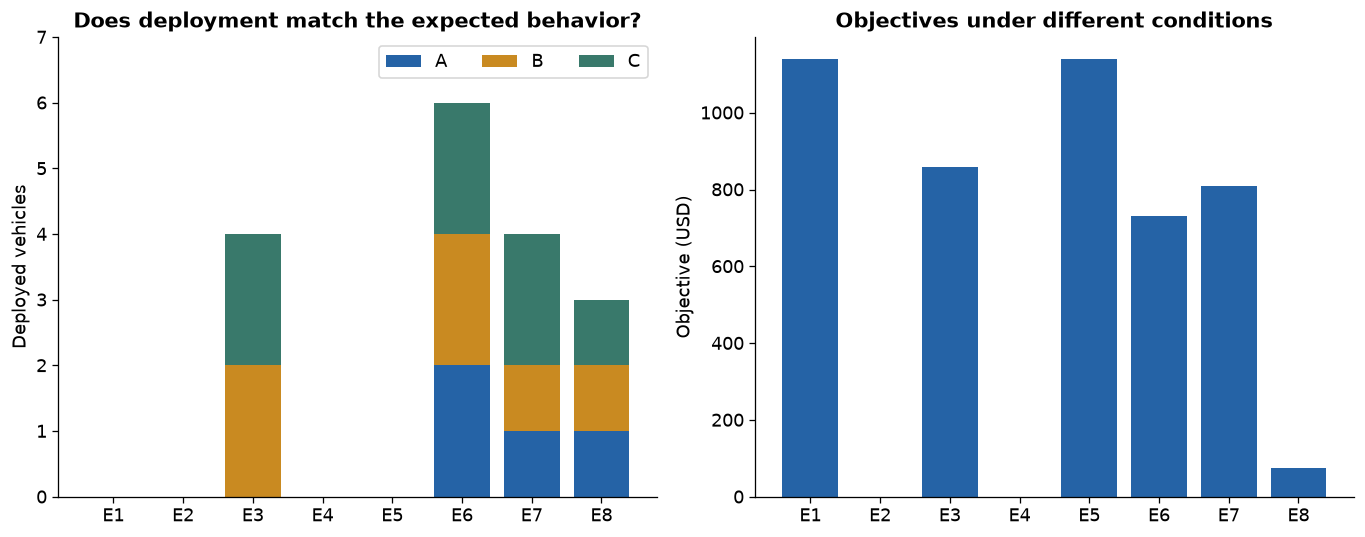

**E1-E8:** No vehicles / zero demand / A prohibited / zero unmet penalty / high entry cost / Q=8 / zero entry cost / demand=10.

**Interpretation:** E1, E4, and E5 all allocate zero vehicles but have different objectives. In E4 the unmet demand coefficient is zero. In E6 the city limits cap allocation at six vehicles even though Q is larger. Objectives with different inputs should not be ranked as comparable business outcomes.

test,condition,expected,implementation_check,expected_property,allocation,service_rate,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
E1,No available vehicles,"No entry, q=0, U=D, objective 1140",PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
E2,Zero demand,"No entry; objective, O, and U all zero",PASS,PASS,"(0, 0, 0)",NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
E3,Allocation to A prohibited,A has y=q=0,PASS,PASS,"(0, 2, 2)",0.3000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
E4,Zero unmet demand penalty,"No entry, objective 0",PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
E5,Very high entry cost,No entry,PASS,PASS,"(0, 0, 0)",0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
E6,Relaxed total fleet limit,"q=(2,2,2), six vehicles allocated",PASS,PASS,"(2, 2, 2)",0.4368,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
E7,Zero entry cost,Every city with vehicles is entered,PASS,PASS,"(1, 1, 2)",0.3070,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
E8,Demand equals one vehicle capacity,"q=(1,1,1), O=U=0, objective 75",PASS,PASS,"(1, 1, 1)",1.0000,60.0000,15.0000,0.0000,0.0000,75.0000,300.0000,225.0000


In [12]:
sa_EDGE_CASES = [
    ('E1','No available vehicles', {'Q':0}, 'No entry, q=0, U=D, objective 1140'),
    ('E2','Zero demand', {'M':np.zeros(3)}, 'No entry; objective, O, and U all zero'),
    ('E3','Allocation to A prohibited', {'qbar':np.array([0,2,2])}, 'A has y=q=0'),
    ('E4','Zero unmet demand penalty', {'c_minus':np.zeros(3)}, 'No entry, objective 0'),
    ('E5','Very high entry cost', {'F':np.full(3,10000.)}, 'No entry'),
    ('E6','Relaxed total fleet limit', {'Q':8}, 'q=(2,2,2), six vehicles allocated'),
    ('E7','Zero entry cost', {'F':np.zeros(3)}, 'Every city with vehicles is entered'),
    ('E8','Demand equals one vehicle capacity', {'p':np.tile(10/sa_BASE['M'],(10,1))},
     'q=(1,1,1), O=U=0, objective 75')]

def sa_check_expected_result(case_id, answer):
                                         
    for r in answer['optima']:
        none = r['q']==(0,0,0) and r['y']==(0,0,0)
        tests = {
            'E1': none and np.allclose(r['O'],0) and np.allclose(r['U'],r['D'])
                  and abs(r['cost']-1140)<sa_TOL,
            'E2': none and abs(r['cost'])<sa_TOL and np.allclose(r['O'],0) and np.allclose(r['U'],0),
            'E3': r['q'][0]==0 and r['y'][0]==0,
            'E4': none and abs(r['cost'])<sa_TOL,
            'E5': none,
            'E6': r['q']==(2,2,2) and r['y']==(1,1,1),
            'E7': all(y==1 for y,q in zip(r['y'],r['q']) if q>0),
            'E8': r['q']==(1,1,1) and np.allclose(r['D'],10)
                  and np.allclose(r['O'],0) and np.allclose(r['U'],0) and abs(r['cost']-75)<sa_TOL,
        }
        if not tests[case_id]: return False
    return True

sa_edge_results, sa_edge_rows = {}, []
for case_id,title,changes,expected in sa_EDGE_CASES:
    data = deepcopy(sa_BASE); data.update(deepcopy(changes))
    answer = sa_solve(data,case_id)
    expected_ok = sa_check_expected_result(case_id, answer)
    assert expected_ok, f'{case_id}: Expected property failed'
    sa_edge_results[case_id] = answer
    r = answer['rep']
    sa_edge_rows.append(dict(test=case_id,condition=title,expected=expected,implementation_check='PASS',
                          expected_property='PASS',allocation=r['q'],service_rate=r['service_rate'],
                          entry_cost=r['components'][0],vehicle_cost=r['components'][1],
                          idle_penalty=r['components'][2],unmet_loss=r['components'][3],
                          objective=r['cost'],no_entry_baseline=r['no_entry'],improvement=r['gain']))
sa_cards([('Implementation check', '8 / 8 PASS'), ('Expected property check', '8 / 8 PASS')])
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
edge_q = np.array([a['rep']['q'] for a in sa_edge_results.values()])
bottom = np.zeros(8)
for c in range(3):
    axes[0].bar(range(8),edge_q[:,c],bottom=bottom,color=CITY_COLORS[c],label=cities[c])
    bottom += edge_q[:,c]
axes[0].set_xticks(range(8),sa_edge_results.keys()); axes[0].set_ylim(0,7)
axes[0].set_ylabel(sa_L('Allocated vehicles','Deployed vehicles')); axes[0].legend(ncols=3)
axes[0].set_title(sa_L('Allocation response by condition', 'Does deployment match the expected behavior?'))
axes[1].bar(range(8),[a['cost'] for a in sa_edge_results.values()],color='#2563A6')
axes[1].set_xticks(range(8),sa_edge_results.keys()); axes[1].set_ylabel(sa_L('Objective (USD)','Objective (USD)'))
axes[1].set_title(sa_L('Objectives under different conditions', 'Objectives under different conditions'))
fig.tight_layout(); sa_showfig(fig,'04_edges')
sa_note('**E1-E8:** No vehicles / zero demand / A prohibited / zero unmet penalty / high entry cost / '
     'Q=8 / zero entry cost / demand=10.\n\n'
     '**Interpretation:** E1, E4, and E5 all allocate zero vehicles but have different objectives. In E4 the unmet demand '
     'coefficient is zero. In E6 the city limits cap allocation at six vehicles even though Q is larger. '
     'Objectives with different inputs should not be ranked as comparable business outcomes.')
sa_detail('E1-E8 conditions and expected properties',pd.DataFrame(sa_edge_rows))

## 3. Sensitivity analysis
Copy baseline inputs, change one parameter, and reoptimize at every setting. Distinguish changes in decisions from changes in operating performance.

Each sweep shows allocation, service rate, objective components, and improvement over no entry, calculated using that setting's demand and cost coefficients.

$$
\text{Improvement}
=
Z_{\text{no entry}}-Z(y,q)
$$


$$
\text{Service rate}(\%)
=
\frac{
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}\min(D_c^s,\kappa_c q_c)
}{
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}D_c^s
}
\times100
$$

$$
\begin{aligned}
\text{Improvement over no entry}
&=
\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}c_c^-D_c^s\\
&\quad-
\left[
\sum_{c\in C}F_cy_c
+\sum_{c\in C}K_cq_c
+\frac{1}{|S|}\sum_{s\in S}\sum_{c\in C}
\left(c_c^+O_c^s+c_c^-U_c^s\right)
\right]
\end{aligned}
$$

Shading spans all optimal solutions. Allocation lines show a representative selected by a fixed rule; expandable tables retain performance ranges across ties.


In [13]:
sa_experiments = {}
def sa_run_sweep(name, values, change):
    results = []
    for value in values:
        data = deepcopy(sa_BASE)
        change(data,float(value))
        answer = sa_solve(data,f'{name}={value:g}')
        results.append((float(value),answer))
    sa_experiments[name] = results
    return results

def sa_full_rows(results):
    rows = []
    for x,a in results:
        for i,r in enumerate(a['optima']):
            rows.append(dict(input_value=x,representative=i==0,y=r['y'],q=r['q'],optimal_count=len(a['optima']),
                service_rate=r['service_rate'],served_demand=r['served'],unmet_demand=r['unmet'],unused_capacity=r['unused'],
                entry_cost=r['components'][0],vehicle_cost=r['components'][1],idle_penalty=r['components'][2],
                unmet_loss=r['components'][3],objective=r['cost'],no_entry_baseline=r['no_entry'],improvement=r['gain']))
    return pd.DataFrame(rows)

def sa_opt_label(a):
    return ' / '.join(str(q) for q in sorted({r['q'] for r in a['optima']}))

def sa_transition_notes(results):
    changes=[]
    for (x0,a0),(x1,a1) in zip(results,results[1:]):
        old={r['q'] for r in a0['optima']}; new={r['q'] for r in a1['optima']}
        if old != new:
            changes.append(f'- **{x0:g} → {x1:g}**: `{sa_opt_label(a0)}` → `{sa_opt_label(a1)}`')
    sa_note('**Sampled intervals where the optimal allocation set changes** (not exact thresholds):\n\n'
         +'\n'.join(changes) if changes else '**Result:** The optimal allocation set is unchanged over the tested range.')

def sa_plot_sweep(results, xlabel, title, filename, reference=None):
    xx=np.array([x for x,a in results]); rr=[a['rep'] for x,a in results]
    fig,axes=plt.subplots(2,2,figsize=(13,8.5))
    ax=axes[0,0]
    for c in range(3):
        vals=[r['q'][c] for r in rr]
        lows=[min(r['q'][c] for r in a['optima']) for x,a in results]
        highs=[max(r['q'][c] for r in a['optima']) for x,a in results]
        ax.plot(xx,vals,marker=['o','s','^'][c],markersize=4,color=CITY_COLORS[c],label=cities[c],
                linestyle=['-','--',':'][c])
        ax.fill_between(xx,lows,highs,color=CITY_COLORS[c],alpha=.10)

    ax.set_ylim(-.12,max(sum(sa_BASE['qbar']),max(sum(r['q']) for r in rr))/2+.2)
    ax.set_yticks(range(4)); ax.legend(ncols=3)
    ax.set_title(sa_L('1. City allocation: line=representative, shading=tie range', '1. Vehicles: lines=representative, bands=ties'))
    ax.set_ylabel(sa_L('Vehicles','Vehicles'))
    ax=axes[0,1]

    lows=[min(r['service_rate'] for r in a['optima'])*100 for x,a in results]
    highs=[max(r['service_rate'] for r in a['optima'])*100 for x,a in results]

    ax.plot(xx,[r['service_rate']*100 for r in rr],color='#2563A6',marker='o',markersize=4)
    ax.fill_between(xx,lows,highs,color='#2563A6',alpha=.15)
    ax.set_ylim(0,100); ax.set_ylabel('%')
    ax.set_title(sa_L('2. Service rate across candidate cities','2. Served share of demand across all candidate cities'))
    ax=axes[1,0]
    for j in range(4):
        ax.plot(xx,[r['components'][j] for r in rr],color=COST_COLORS[j] if j<3 else '#64748B',
                label=sa_component_labels[j],linestyle=['-','--',':','-.'][j])

    ax.plot(xx,[r['cost'] for r in rr],color='#172B40',linewidth=2.2,label=sa_L('Total','Total'))
    ax.set_ylim(bottom=0);ax.set_ylabel('USD');ax.legend(fontsize=9,ncols=2)
    ax.set_title(sa_L('3. Objective components, including opportunity loss','3. Objective components, including opportunity loss'))
    ax=axes[1,1]
    ax.plot(xx,[r['gain'] for r in rr],color='#39796B',marker='o',markersize=4)
    ax.axhline(0,color='#64748B',linewidth=.8);ax.set_ylim(bottom=0);ax.set_ylabel('USD')
    ax.set_title(sa_L('4. Improvement over no entry','4. Improvement over no entry under the same conditions'))

    for ax in axes.flat:
        ax.set_xlabel(xlabel);ax.grid(axis='y',alpha=.18)
        if reference is not None:ax.axvline(reference,color='#64748B',linestyle=':',alpha=.7)
    fig.suptitle(title,fontsize=15)
    fig.text(.5,.01,sa_L('Points are evaluated settings; lines connect points; shading spans optimal solutions, not confidence intervals',
                      'Points are evaluated settings; lines connect them. Bands show tied optima, not confidence intervals.'),
             ha='center',fontsize=10)
    fig.tight_layout(rect=[0,.04,1,.95]);sa_showfig(fig,filename)
    sa_transition_notes(results)
    sa_detail('Full results and all tied optimal allocations',sa_full_rows(results))

### 3-1. Fleet availability: Q
Q is an upper bound on available vehicles, not a required allocation. Sweep Q from 0 to 8 in unit increments, holding each city limit at 2.

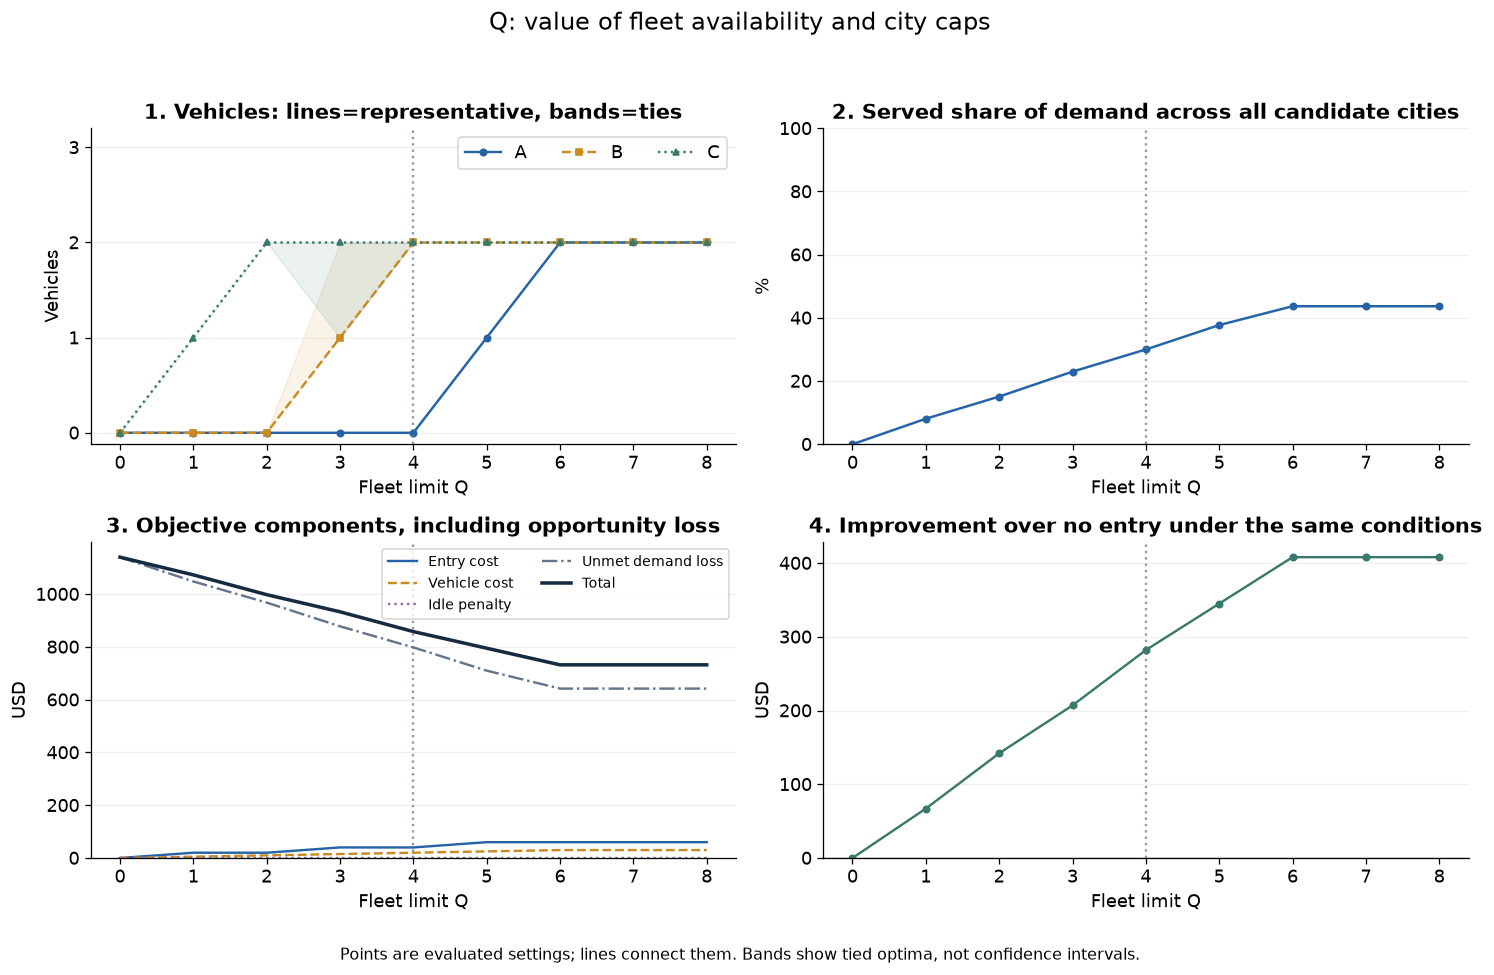

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **0 → 1**: `(0, 0, 0)` → `(0, 0, 1)`
- **1 → 2**: `(0, 0, 1)` → `(0, 0, 2)`
- **2 → 3**: `(0, 0, 2)` → `(0, 1, 2) / (0, 2, 1)`
- **3 → 4**: `(0, 1, 2) / (0, 2, 1)` → `(0, 2, 2)`
- **4 → 5**: `(0, 2, 2)` → `(1, 2, 2)`
- **5 → 6**: `(1, 2, 2)` → `(2, 2, 2)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.0000,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000
1.0000,True,"(0, 0, 1)","(0, 0, 1)",1,0.0807,9.2000,104.8000,0.8000,20.0000,5.0000,0.0000,"1,048.0000","1,073.0000","1,140.0000",67.0000
2.0000,True,"(0, 0, 1)","(0, 0, 2)",1,0.1509,17.2000,96.8000,2.8000,20.0000,10.0000,0.0000,968.0000,998.0000,"1,140.0000",142.0000
3.0000,True,"(0, 1, 1)","(0, 1, 2)",2,0.2298,26.2000,87.8000,3.8000,40.0000,15.0000,0.0000,878.0000,933.0000,"1,140.0000",207.0000
3.0000,False,"(0, 1, 1)","(0, 2, 1)",2,0.2298,26.2000,87.8000,3.8000,40.0000,15.0000,0.0000,878.0000,933.0000,"1,140.0000",207.0000
4.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
5.0000,True,"(1, 1, 1)","(1, 2, 2)",1,0.3772,43.0000,71.0000,7.0000,60.0000,25.0000,0.0000,710.0000,795.0000,"1,140.0000",345.0000
6.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
7.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000
8.0000,True,"(1, 1, 1)","(2, 2, 2)",1,0.4368,49.8000,64.2000,10.2000,60.0000,30.0000,0.0000,642.0000,732.0000,"1,140.0000",408.0000


**Interpretation:** Q=4 gives `[0,2,2]`, Q=5 gives `[1,2,2]`, and Q=6 gives `[2,2,2]`. The improvement from Q=4 to Q=5 is USD 63; beyond Q=6 the city limits prevent further improvement. This is the **model value of additional fleet availability after the specified vehicle cost**. It is not a vehicle purchase price. At Q=3, `[0,1,2]` and `[0,2,1]` are tied.

In [14]:
sa_q_results=sa_run_sweep('Q',np.arange(9),lambda d,v:d.update(Q=int(v)))
sa_plot_sweep(sa_q_results,sa_L('Fleet limit Q (vehicles)','Fleet limit Q'),
           sa_L('Q: fleet availability and city limits','Q: value of fleet availability and city caps'), '05_Q',4)
q_cost=np.array([a['cost'] for x,a in sa_q_results])
assert np.all(np.diff(q_cost)<=sa_TOL)
assert np.allclose(q_cost[6:],732)
sa_note('**Interpretation:** Q=4 gives `[0,2,2]`, Q=5 gives `[1,2,2]`, and Q=6 gives `[2,2,2]`. '
     'The improvement from Q=4 to Q=5 is USD 63; beyond Q=6 the city limits prevent further improvement. '
     'This is the **model value of additional fleet availability after the specified vehicle cost**. '
     'It is not a vehicle purchase price. At Q=3, `[0,1,2]` and `[0,2,1]` are tied.')

### 3-2. Entry costs: F
Apply the same F to all cities. Examine 0 to 20 in detail and larger values up to no entry. Compare exact cost functions to verify the switch at F=8.

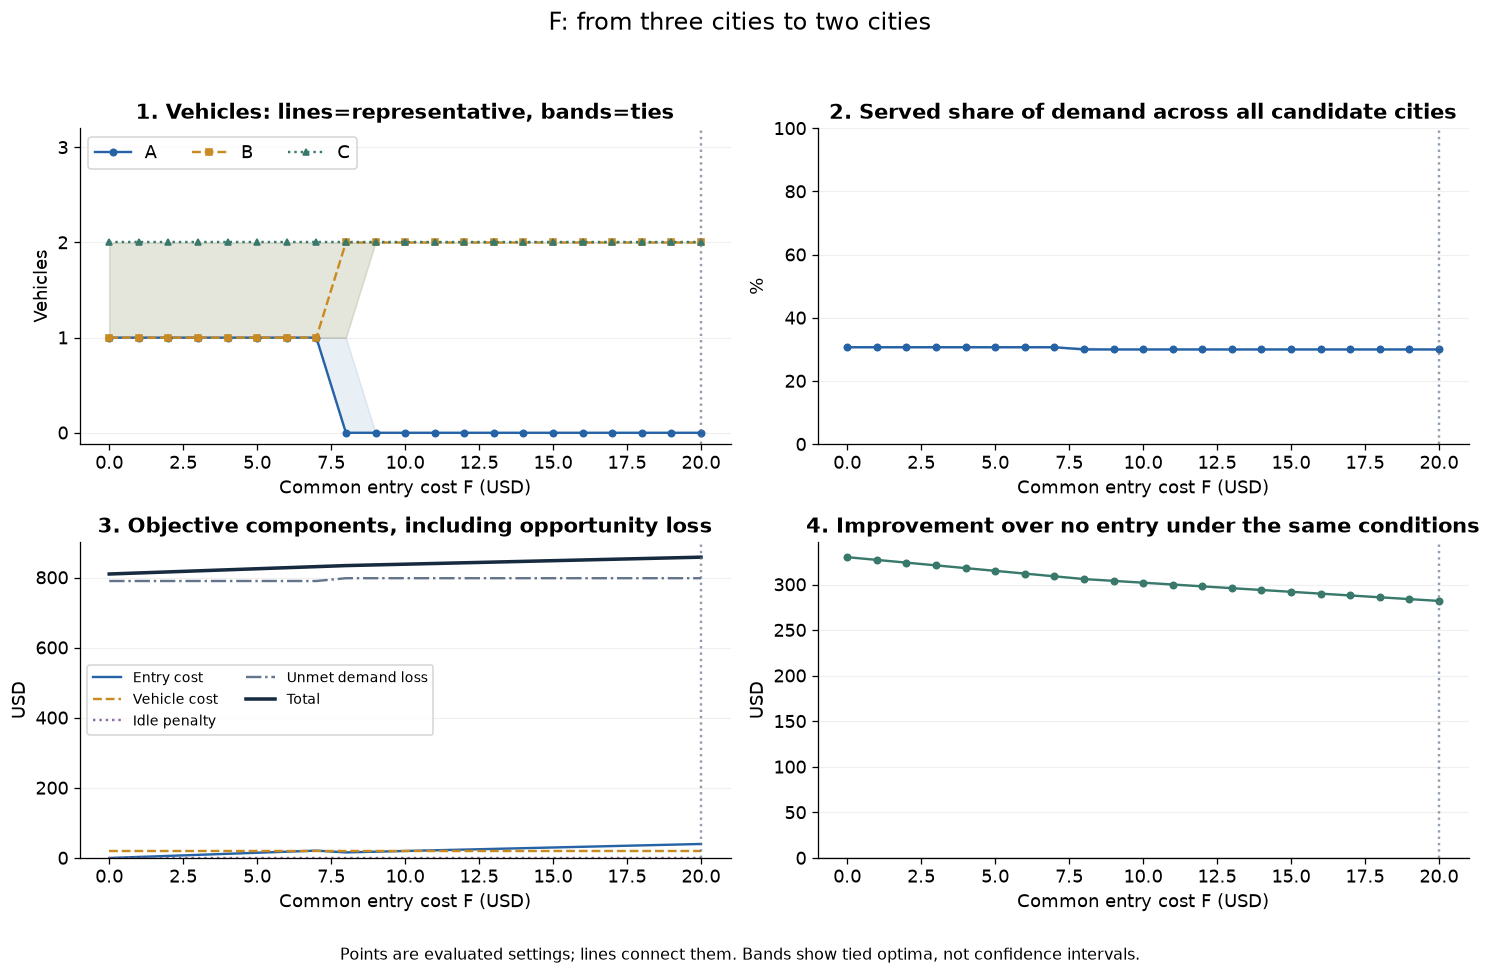

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **7 → 8**: `(1, 1, 2) / (1, 2, 1)` → `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)`
- **8 → 9**: `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)` → `(0, 2, 2)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
0.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
1.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
1.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
2.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
2.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
3.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
3.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
4.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000
4.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000


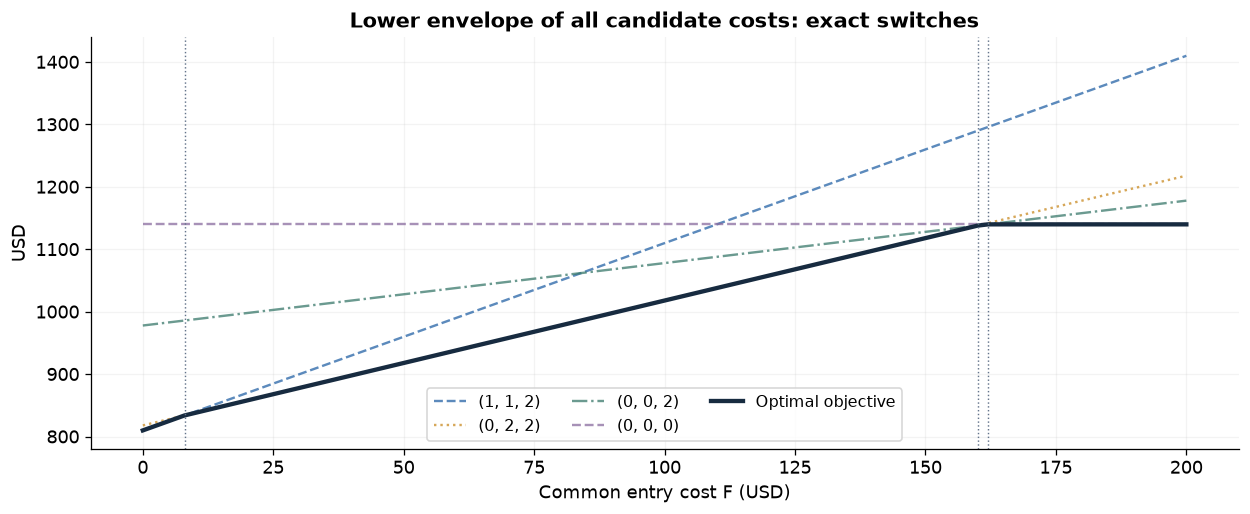

**Exact cost functions:** `[1,1,2]` costs `810+3F`; `[0,2,2]` costs `818+2F`. They tie at **F=8**, where the value of additional service equals the additional entry cost. Three-city entry is preferable just below 8; two-city entry is preferable just above 8.

**Switching points from all candidate cost functions:** 8, 160, 162 USD. At higher entry costs, entry into C alone becomes optimal, followed by no entry. Each line in the full-range plot is the exact cost function of a fixed allocation.

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **159 → 160**: `(0, 2, 2)` → `(0, 0, 2) / (0, 2, 2)`
- **160 → 161**: `(0, 0, 2) / (0, 2, 2)` → `(0, 0, 2)`
- **161 → 162**: `(0, 0, 2)` → `(0, 0, 0) / (0, 0, 2)`
- **162 → 163**: `(0, 0, 0) / (0, 0, 2)` → `(0, 0, 0)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
0.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,0.0000,20.0000,0.0000,790.0000,810.0000,"1,140.0000",330.0000
1.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
1.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,3.0000,20.0000,0.0000,790.0000,813.0000,"1,140.0000",327.0000
2.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
2.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,6.0000,20.0000,0.0000,790.0000,816.0000,"1,140.0000",324.0000
3.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
3.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,9.0000,20.0000,0.0000,790.0000,819.0000,"1,140.0000",321.0000
4.0000,True,"(1, 1, 1)","(1, 1, 2)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000
4.0000,False,"(1, 1, 1)","(1, 2, 1)",2,0.3070,35.0000,79.0000,5.0000,12.0000,20.0000,0.0000,790.0000,822.0000,"1,140.0000",318.0000


In [15]:
f_values=sorted(set(list(np.arange(0,21,1))+[40,80,120,150,155,159,160,161,162,163,170,200]))
sa_f_results=sa_run_sweep('F',f_values,lambda d,v:d.update(F=np.full(3,v)))
sa_plot_sweep([r for r in sa_f_results if r[0]<=20], sa_L('Common entry cost F (USD/city)','Common entry cost F (USD)'),
           sa_L('F: three-city entry versus two-city concentration','F: from three cities to two cities'), '06_F_zoom',20)
                                                    
fzero=deepcopy(sa_BASE);fzero['F']=np.zeros(3)
lines=sa_enumerate_decisions(fzero)
crossings=set()
for r in lines:
    for t in lines:
        slope=sum(r['y'])-sum(t['y'])
        if slope:
            crossing=(t['cost']-r['cost'])/slope
            if 0<crossing<200:
                vals=[u['cost']+sum(u['y'])*crossing for u in lines]
                if abs(r['cost']+sum(r['y'])*crossing-min(vals))<sa_TOL:
                    crossings.add(round(crossing,9))
sa_f_thresholds=sorted(crossings)
fig,ax=plt.subplots(figsize=(11,4.6))
strategies=[((1,1,1),(1,1,2)),((0,1,1),(0,2,2)),((0,0,1),(0,0,2)),((0,0,0),(0,0,0))]
grid=np.linspace(0,200,401)
for i,(strategy_y,strategy_q) in enumerate(strategies):
    intercept=sa_evaluate(fzero,strategy_y,strategy_q)['cost']
    ax.plot(grid,intercept+sum(strategy_y)*grid,label=str(strategy_q),color=['#2563A6','#C98A21','#39796B','#8A6C9F'][i],
            linestyle=['--',':','-.','--'][i],alpha=.75)
envelope=np.min([[r['cost']+sum(r['y'])*v for v in grid] for r in lines],axis=0)
ax.plot(grid,envelope,color='#172B40',linewidth=2.7,label=sa_L('Optimal objective','Optimal objective'))
for x in sa_f_thresholds:ax.axvline(x,color='#64748B',linewidth=.9,linestyle=':')
ax.set_xlabel(sa_L('Common entry cost F (USD)','Common entry cost F (USD)'));ax.set_ylabel('USD')
ax.set_title(sa_L('Lower envelope of candidate cost functions','Lower envelope of all candidate costs: exact switches'))
ax.legend(ncols=3,fontsize=10);ax.grid(alpha=.15);fig.tight_layout();sa_showfig(fig,'07_F_full')
sa_note('**Exact cost functions:** `[1,1,2]` costs `810+3F`; `[0,2,2]` costs `818+2F`. '
     'They tie at **F=8**, where the value of additional service equals the additional entry cost. '
     'Three-city entry is preferable just below 8; two-city entry is preferable just above 8.\n\n'
     '**Switching points from all candidate cost functions:** '+', '.join(f'{x:g}' for x in sa_f_thresholds)+' USD. '
     'At higher entry costs, entry into C alone becomes optimal, followed by no entry. '
     'Each line in the full-range plot is the exact cost function of a fixed allocation.')
sa_transition_notes([r for r in sa_f_results if r[0]>=20])
sa_detail('Full F range: allocation, service, costs, and improvement',sa_full_rows(sa_f_results))

### 3-3. Vehicle productivity: kappa
Sweep common kappa from 5 to 20 in increments of 0.5, holding fleet size and costs fixed. With c_plus=0, increasing capacity for a fixed allocation cannot raise the optimal objective. This property need not hold with a positive idle penalty.

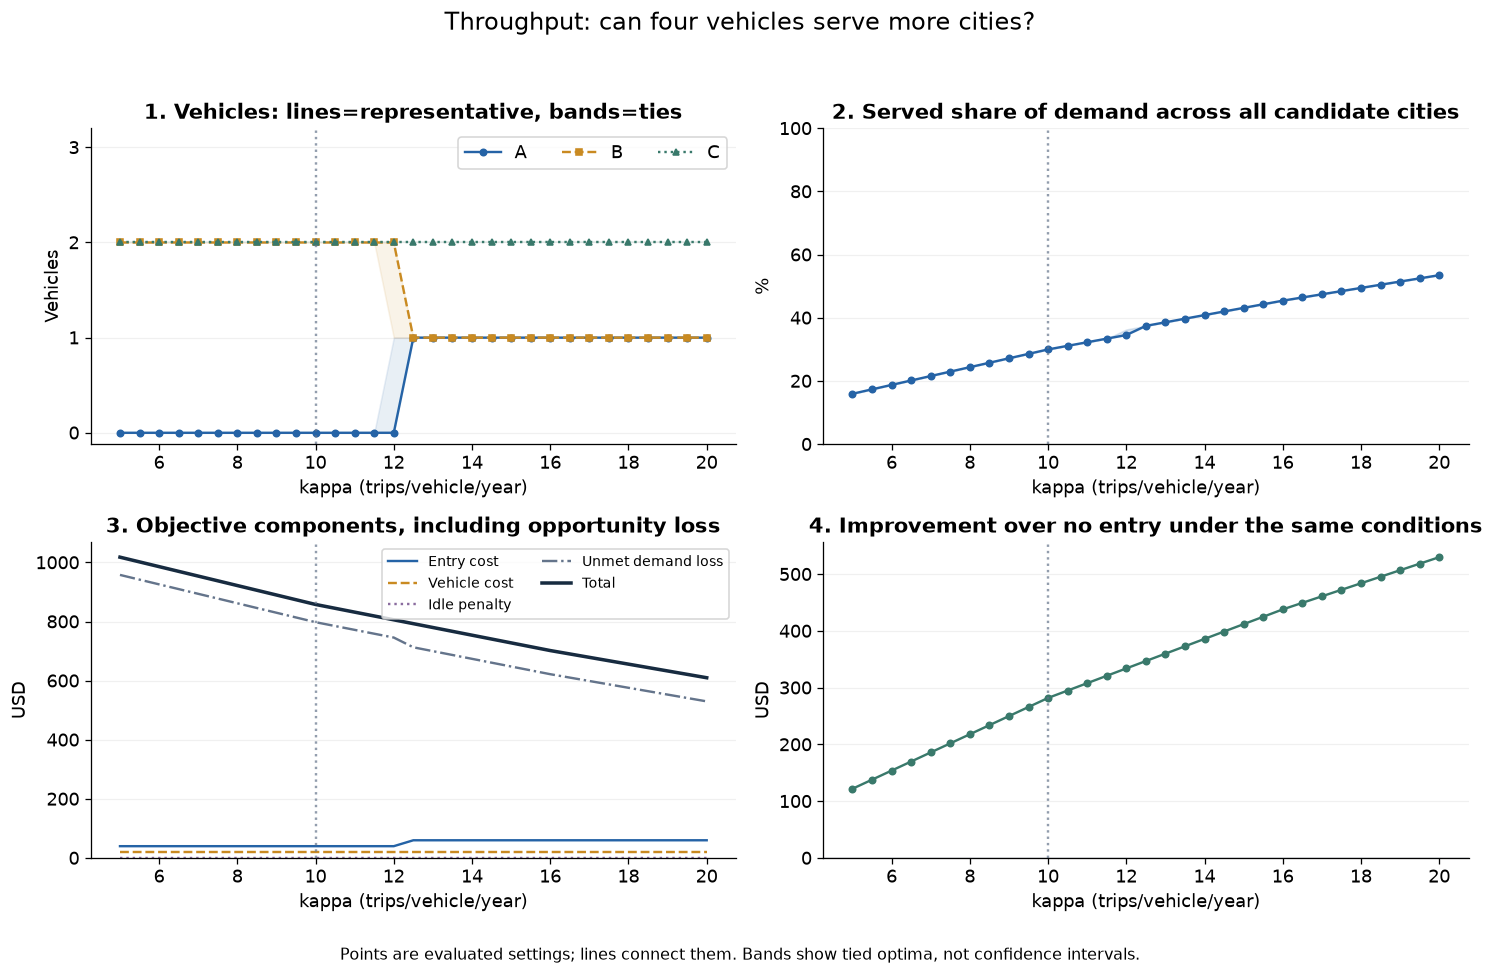

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **11.5 → 12**: `(0, 2, 2)` → `(0, 2, 2) / (1, 1, 2)`
- **12 → 12.5**: `(0, 2, 2) / (1, 1, 2)` → `(1, 1, 2)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
5.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,18.2000,95.8000,1.8000,40.0000,20.0000,0.0000,958.0000,"1,018.0000","1,140.0000",122.0000
5.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1737,19.8000,94.2000,2.2000,40.0000,20.0000,0.0000,942.0000,"1,002.0000","1,140.0000",138.0000
6.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.1877,21.4000,92.6000,2.6000,40.0000,20.0000,0.0000,926.0000,986.0000,"1,140.0000",154.0000
6.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2018,23.0000,91.0000,3.0000,40.0000,20.0000,0.0000,910.0000,970.0000,"1,140.0000",170.0000
7.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2158,24.6000,89.4000,3.4000,40.0000,20.0000,0.0000,894.0000,954.0000,"1,140.0000",186.0000
7.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2298,26.2000,87.8000,3.8000,40.0000,20.0000,0.0000,878.0000,938.0000,"1,140.0000",202.0000
8.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2439,27.8000,86.2000,4.2000,40.0000,20.0000,0.0000,862.0000,922.0000,"1,140.0000",218.0000
8.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2579,29.4000,84.6000,4.6000,40.0000,20.0000,0.0000,846.0000,906.0000,"1,140.0000",234.0000
9.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2719,31.0000,83.0000,5.0000,40.0000,20.0000,0.0000,830.0000,890.0000,"1,140.0000",250.0000
9.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.2860,32.6000,81.4000,5.4000,40.0000,20.0000,0.0000,814.0000,874.0000,"1,140.0000",266.0000


**Interpretation:** kappa=10 gives `[0,2,2]`; kappa=20 gives `[1,1,2]`. Higher productivity can make the first vehicle in A more valuable than the second vehicle in B. At kappa=20 the service rate is about 53.5% and the objective is 610. Unused capacity and served demand both increase, so unused capacity alone does not establish inefficiency. The two allocations tie at kappa=12; three-city entry is optimal at the sampled setting 12.5. Near kappa=12, the first vehicle in A serves an additional `0.8+0.8*kappa` trips on average, while the second vehicle in B serves `6+0.2*kappa` trips. Moving one vehicle from B to A therefore yields `10*(0.6*kappa-5.2)-20 = 6*kappa-72`, which is zero at kappa=12. This expression applies only to the corresponding demand interval.

In [16]:
sa_k_results=sa_run_sweep('kappa',np.arange(5,20.01,.5),lambda d,v:d.update(kappa=np.full(3,v)))
sa_plot_sweep(sa_k_results,sa_L('Vehicle productivity (trips/vehicle/year)','kappa (trips/vehicle/year)'),
           sa_L('kappa: broader service with the same four vehicles','Throughput: can four vehicles serve more cities?'),
           '08_kappa',10)
assert np.all(np.diff([a['cost'] for x,a in sa_k_results])<=sa_TOL)
assert sa_k_results[-1][1]['rep']['q']==(1,1,2)
sa_note('**Interpretation:** kappa=10 gives `[0,2,2]`; kappa=20 gives `[1,1,2]`. '
     'Higher productivity can make the first vehicle in A more valuable than the second vehicle in B. '
     'At kappa=20 the service rate is about 53.5% and the objective is 610. '
     'Unused capacity and served demand both increase, so unused capacity alone does not establish inefficiency. '
     'The two allocations tie at kappa=12; three-city entry is optimal at the sampled setting 12.5. '
     'Near kappa=12, the first vehicle in A serves an additional `0.8+0.8*kappa` trips on average, while the second vehicle in B serves '
     '`6+0.2*kappa` trips. Moving one vehicle from B to A therefore yields '
     '`10*(0.6*kappa-5.2)-20 = 6*kappa-72`, which is zero at kappa=12. '
     'This expression applies only to the corresponding demand interval.')

### 3-4. Market size in A: M_A
Vary only M_A from 0.5 to 2 times its baseline value of 80. Hold M_B, M_C, and all choice probabilities fixed. This changes both the mean and dispersion of demand; the variability experiment below isolates dispersion at a fixed mean.

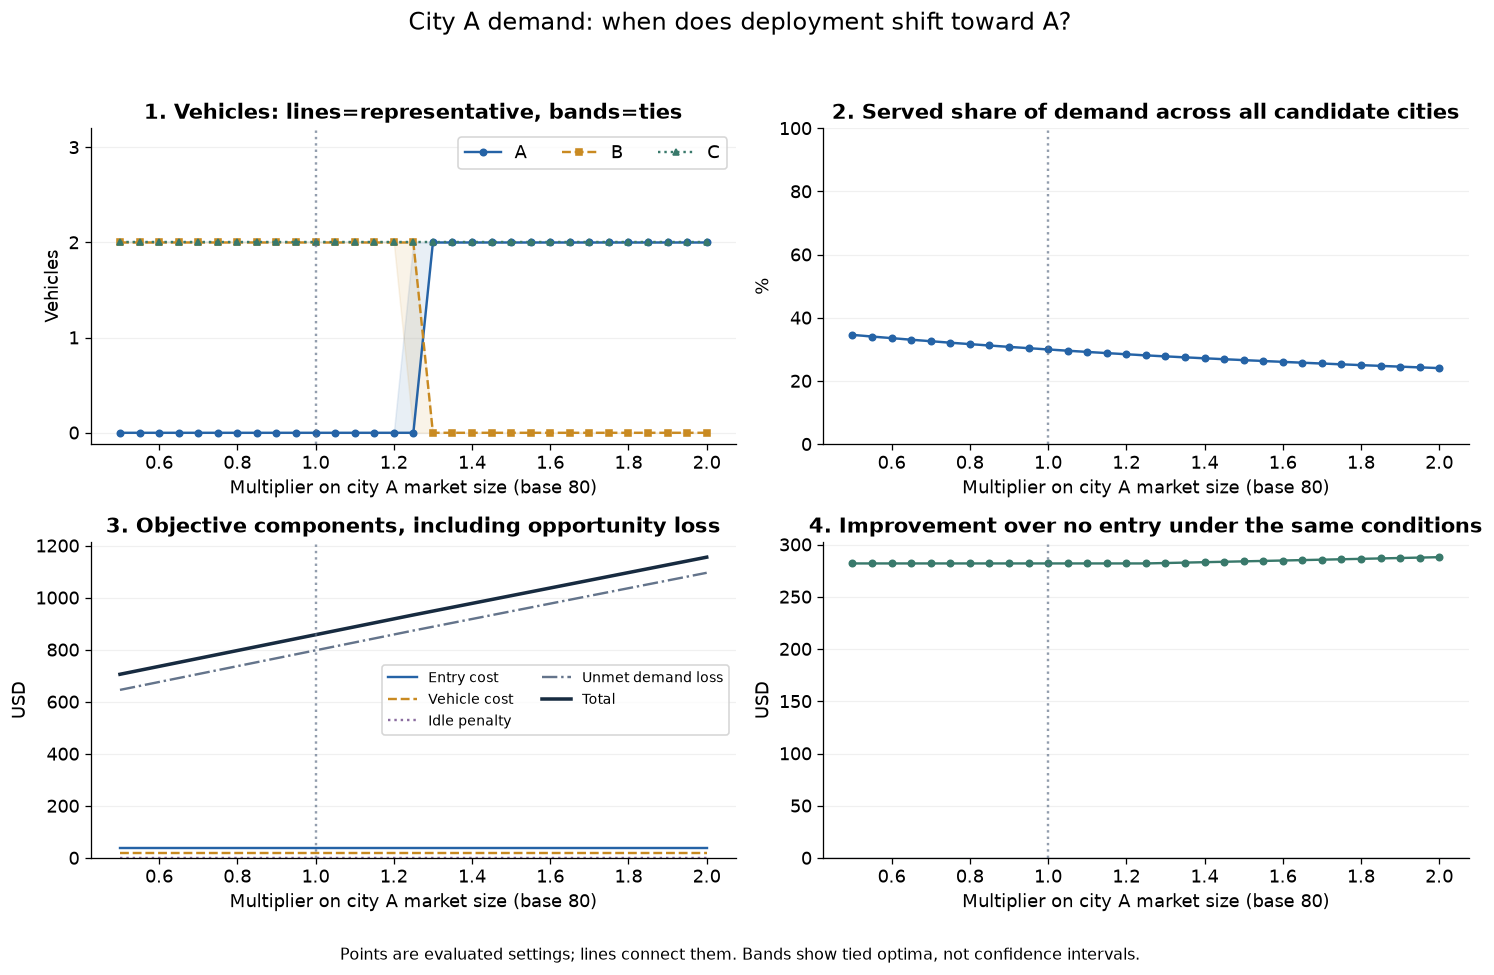

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **1.2 → 1.25**: `(0, 2, 2)` → `(0, 2, 2) / (2, 0, 2)`
- **1.25 → 1.3**: `(0, 2, 2) / (2, 0, 2)` → `(2, 0, 2)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3462,34.2000,64.6000,5.8000,40.0000,20.0000,0.0000,646.0000,706.0000,988.0000,282.0000
0.5500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3409,34.2000,66.1200,5.8000,40.0000,20.0000,0.0000,661.2000,721.2000,"1,003.2000",282.0000
0.6000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3358,34.2000,67.6400,5.8000,40.0000,20.0000,0.0000,676.4000,736.4000,"1,018.4000",282.0000
0.6500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3309,34.2000,69.1600,5.8000,40.0000,20.0000,0.0000,691.6000,751.6000,"1,033.6000",282.0000
0.7000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3261,34.2000,70.6800,5.8000,40.0000,20.0000,0.0000,706.8000,766.8000,"1,048.8000",282.0000
0.7500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3214,34.2000,72.2000,5.8000,40.0000,20.0000,0.0000,722.0000,782.0000,"1,064.0000",282.0000
0.8000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3169,34.2000,73.7200,5.8000,40.0000,20.0000,0.0000,737.2000,797.2000,"1,079.2000",282.0000
0.8500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3125,34.2000,75.2400,5.8000,40.0000,20.0000,0.0000,752.4000,812.4000,"1,094.4000",282.0000
0.9000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3082,34.2000,76.7600,5.8000,40.0000,20.0000,0.0000,767.6000,827.6000,"1,109.6000",282.0000
0.9500,True,"(0, 1, 1)","(0, 2, 2)",1,0.3041,34.2000,78.2800,5.8000,40.0000,20.0000,0.0000,782.8000,842.8000,"1,124.8000",282.0000


**Interpretation:** At **1.25 times baseline (M_A=100)**, `[0,2,2]` and `[2,0,2]` tie. At **1.30 times baseline (M_A=104)**, `[2,0,2]` is optimal, shifting both B vehicles to A. At multiplier 1.25, A and B both have M=100 and identical marginal p distributions, so equal fleet sizes provide equal expected service and costs. Q remains 4; demand growth does not increase fleet availability. Demand growth also raises the no-entry loss, so a higher objective alone does not indicate a worse strategy. Read **service rate and improvement over no entry together**.

In [17]:
def sa_change_a(data,multiplier):
    data['M'][0]=sa_BASE['M'][0]*multiplier
sa_a_results=sa_run_sweep('M_A multiplier',np.round(np.arange(.5,2.001,.05),2),sa_change_a)
sa_plot_sweep(sa_a_results,sa_L('A market size multiplier (baseline 80)','Multiplier on city A market size (base 80)'),
           sa_L('M_A: allocation response to market growth in A',
             'City A demand: when does deployment shift toward A?'),'09_A_market',1)
sa_note('**Interpretation:** At **1.25 times baseline (M_A=100)**, `[0,2,2]` and `[2,0,2]` tie. '
     'At **1.30 times baseline (M_A=104)**, `[2,0,2]` is optimal, shifting both B vehicles to A. '
     'At multiplier 1.25, A and B both have M=100 and identical marginal p distributions, '
     'so equal fleet sizes provide equal expected service and costs. Q remains 4; demand growth does not increase fleet availability. '
     'Demand growth also raises the no-entry loss, so a higher objective alone does not indicate a worse strategy. '
     'Read **service rate and improvement over no entry together**.')

### 3-5. Idle penalty: c_plus
Increase the common idle penalty from 0 to 20 in increments of 0.5. Hold all other inputs fixed and reoptimize at each setting.


Allocation and operating performance by c+

Cost and improvement by c+ (USD)

Performance changes relative to c+=0
The baseline is zero, so the sweep increases c+ from zero.
Idle costs and improvement can change even when the allocation is unchanged.
The table reports representative optima; the expandable results include all optima.
Refine sampled intervals to locate allocation changes more precisely.


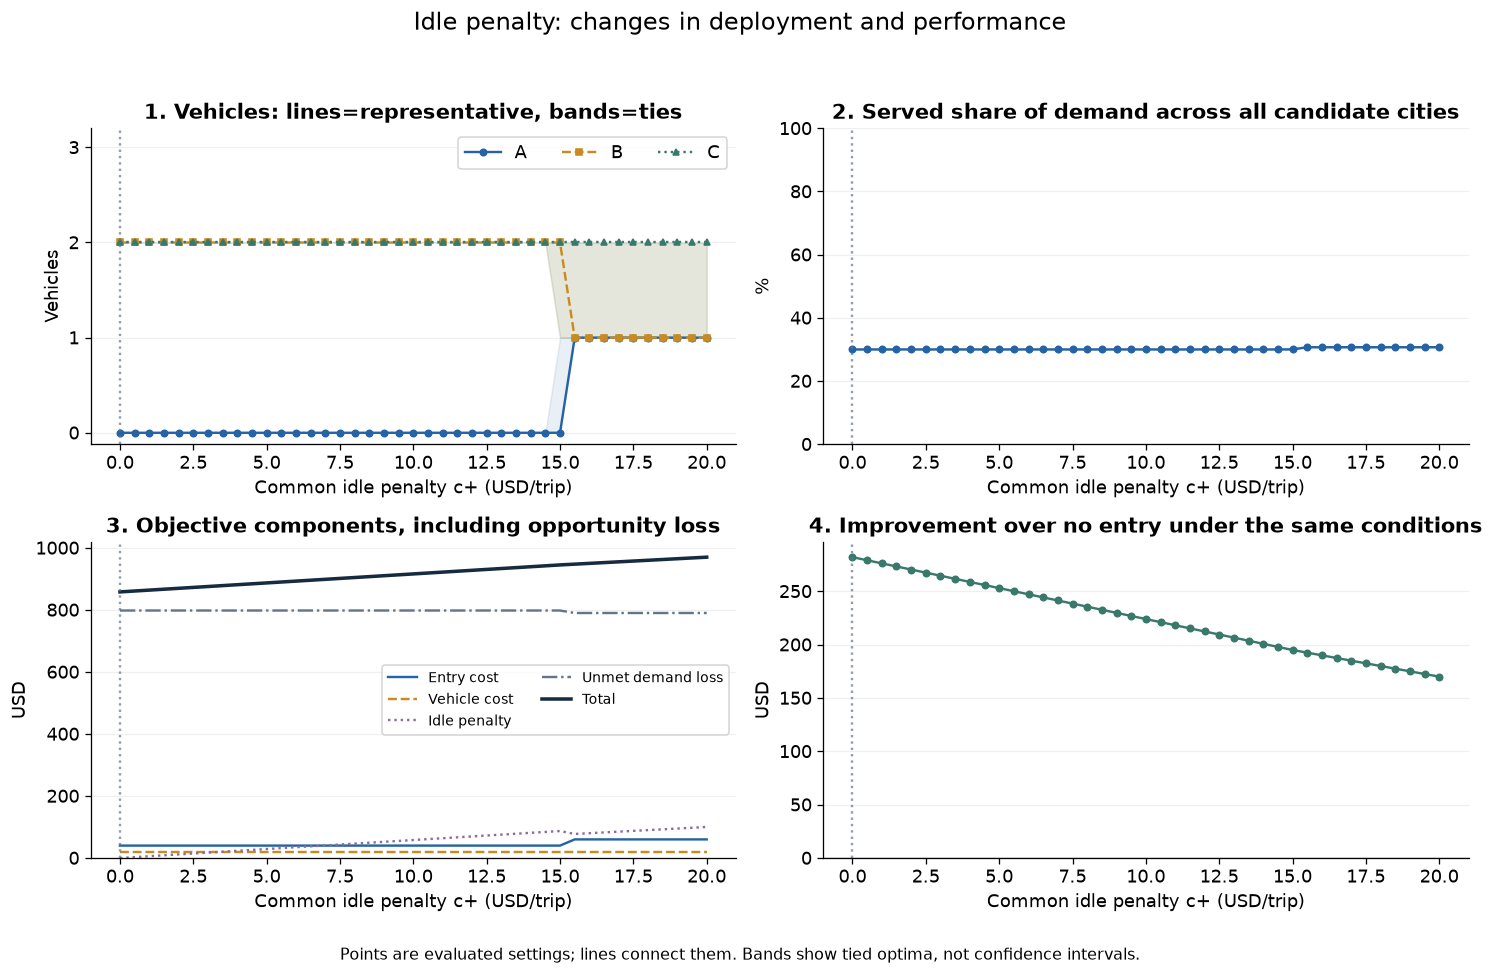

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **14.5 → 15**: `(0, 2, 2)` → `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)`
- **15 → 15.5**: `(0, 2, 2) / (1, 1, 2) / (1, 2, 1)` → `(1, 1, 2) / (1, 2, 1)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000
0.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,2.9000,798.0000,860.9000,"1,140.0000",279.1000
1.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,5.8000,798.0000,863.8000,"1,140.0000",276.2000
1.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,8.7000,798.0000,866.7000,"1,140.0000",273.3000
2.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,11.6000,798.0000,869.6000,"1,140.0000",270.4000
2.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,14.5000,798.0000,872.5000,"1,140.0000",267.5000
3.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,17.4000,798.0000,875.4000,"1,140.0000",264.6000
3.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,20.3000,798.0000,878.3000,"1,140.0000",261.7000
4.0000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,23.2000,798.0000,881.2000,"1,140.0000",258.8000
4.5000,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,26.1000,798.0000,884.1000,"1,140.0000",255.9000


,c+ (USD/trip),"Representative allocation (A,B,C)",All optimal allocations,Mean served demand,Service rate (%),Mean unused capacity
0,0.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
1,0.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
2,1.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
3,1.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
4,2.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
5,2.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
6,3.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
7,3.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
8,4.0,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8
9,4.5,"(0, 2, 2)","(0, 2, 2)",34.2,30.000,5.8


,c+ (USD/trip),Entry cost,Vehicle cost,Idle penalty,Unmet demand loss,Objective,Improvement over no entry
0,0.0,40.0,20.0,0.0,798.0,858.0,282.0
1,0.5,40.0,20.0,2.9,798.0,860.9,279.1
2,1.0,40.0,20.0,5.8,798.0,863.8,276.2
3,1.5,40.0,20.0,8.7,798.0,866.7,273.3
4,2.0,40.0,20.0,11.6,798.0,869.6,270.4
5,2.5,40.0,20.0,14.5,798.0,872.5,267.5
6,3.0,40.0,20.0,17.4,798.0,875.4,264.6
7,3.5,40.0,20.0,20.3,798.0,878.3,261.7
8,4.0,40.0,20.0,23.2,798.0,881.2,258.8
9,4.5,40.0,20.0,26.1,798.0,884.1,255.9


,c+ (USD/trip),Change in served demand from baseline,Change in service rate (pp),Change in objective from baseline,Change in improvement from baseline
0,0.0,0.0,0.000,0.0,0.0
1,0.5,0.0,0.000,2.9,-2.9
2,1.0,0.0,0.000,5.8,-5.8
3,1.5,0.0,0.000,8.7,-8.7
4,2.0,0.0,0.000,11.6,-11.6
5,2.5,0.0,0.000,14.5,-14.5
6,3.0,0.0,0.000,17.4,-17.4
7,3.5,0.0,0.000,20.3,-20.3
8,4.0,0.0,0.000,23.2,-23.2
9,4.5,0.0,0.000,26.1,-26.1


In [18]:
               
                                  
                                               
                                         
                   

cplus_values = np.arange(0.0, 20.01, 0.5)

def change_cplus(data, value):
    data["c_plus"] = np.full_like(
        data["c_plus"], value, dtype=float
    )

cplus_results = sa_run_sweep(
    "c_plus",
    cplus_values,
    change_cplus,
)

                       
                                
sa_plot_sweep(
    cplus_results,
    sa_L(
        'Common idle penalty c+ (USD/trip)',
        "Common idle penalty c+ (USD/trip)",
    ),
    sa_L(
        'c+: allocation and performance with a penalty on unused capacity',
        "Idle penalty: changes in deployment and performance",
    ),
    "13_cplus",
    reference=0,
)

                             
cplus_reference = cplus_results[0][1]["rep"]
cplus_rows = []

for value, answer in cplus_results:
    metrics = answer["rep"]

    cplus_rows.append({
        'c+ (USD/trip)': value,
        'Representative allocation (A,B,C)': metrics["q"],
        'All optimal allocations': sa_opt_label(answer),
        'Mean served demand': metrics["served"],
        'Service rate (%)': 100 * metrics["service_rate"],
        'Mean unused capacity': metrics["unused"],
        'Entry cost': metrics["components"][0],
        'Vehicle cost': metrics["components"][1],
        'Idle penalty': metrics["components"][2],
        'Unmet demand loss': metrics["components"][3],
        'Objective': metrics["cost"],
        'Improvement over no entry': metrics["gain"],
        'Change in served demand from baseline':
            metrics["served"] - cplus_reference["served"],
        'Change in service rate (pp)':
            100 * (
                metrics["service_rate"]
                - cplus_reference["service_rate"]
            ),
        'Change in objective from baseline':
            metrics["cost"] - cplus_reference["cost"],
        'Change in improvement from baseline':
            metrics["gain"] - cplus_reference["gain"],
    })

cplus_summary = pd.DataFrame(cplus_rows)

show(
    'Allocation and operating performance by c+',
    cplus_summary[[
        'c+ (USD/trip)',
        'Representative allocation (A,B,C)',
        'All optimal allocations',
        'Mean served demand',
        'Service rate (%)',
        'Mean unused capacity',
    ]].round(3),
)

show(
    'Cost and improvement by c+ (USD)',
    cplus_summary[[
        'c+ (USD/trip)',
        'Entry cost',
        'Vehicle cost',
        'Idle penalty',
        'Unmet demand loss',
        'Objective',
        'Improvement over no entry',
    ]].round(3),
)

show(
    'Performance changes relative to c+=0',
    cplus_summary[[
        'c+ (USD/trip)',
        'Change in served demand from baseline',
        'Change in service rate (pp)',
        'Change in objective from baseline',
        'Change in improvement from baseline',
    ]].round(3),
)

                                   
                                 
assert np.all(
    np.diff(cplus_summary['Objective'].to_numpy()) >= -sa_TOL
), 'Objective must not decrease as c+ increases.'

print('The baseline is zero, so the sweep increases c+ from zero.')
print('Idle costs and improvement can change even when the allocation is unchanged.')
print('The table reports representative optima; the expandable results include all optima.')
print('Refine sampled intervals to locate allocation changes more precisely.')

### 3-6. Demand variability: alpha
$$p(\alpha)=\bar p+\alpha(p-\bar p),\qquad 0\le\alpha\le1.$$
At alpha=0 demand equals its mean; alpha=1 restores the original scenarios. Only dispersion changes: scenario count, means, and occurrence probabilities remain fixed. No new demand samples are drawn.


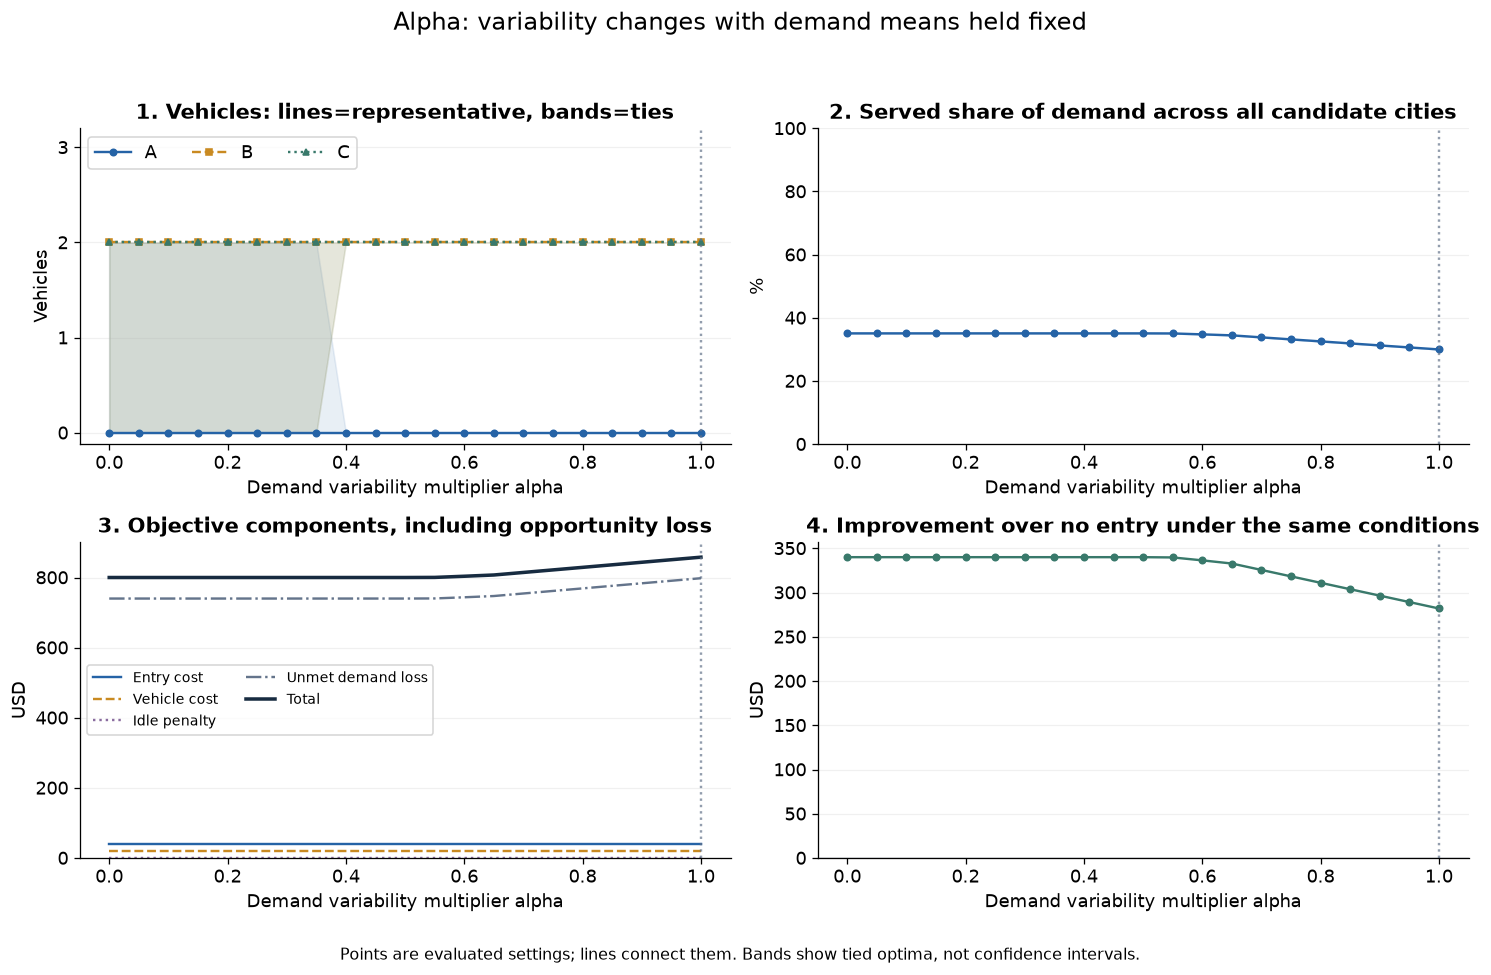

**Sampled intervals where the optimal allocation set changes** (not exact thresholds):

- **0.35 → 0.4**: `(0, 2, 2) / (2, 0, 2) / (2, 2, 0)` → `(0, 2, 2)`

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement
0.0000,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0000,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0000,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.0500,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,False,"(1, 0, 1)","(2, 0, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1000,False,"(1, 1, 0)","(2, 2, 0)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000
0.1500,True,"(0, 1, 1)","(0, 2, 2)",3,0.3509,40.0000,74.0000,0.0000,40.0000,20.0000,0.0000,740.0000,800.0000,"1,140.0000",340.0000


**Interpretation:** At alpha=0 the three two-city allocations tie. At the original variability alpha=1, only `[0,2,2]` is optimal, and the objective increases from 800 to 858. The representative allocation can remain unchanged while the **optimal set and operating performance** change. Greater variability in this instance creates both unused capacity and unmet demand.

In [19]:
sa_mean_p=sa_BASE['p'].mean(axis=0,keepdims=True)
def sa_change_alpha(data,alpha):
    data['p']=sa_mean_p+alpha*(sa_BASE['p']-sa_mean_p)
    assert np.allclose(data['p'].mean(axis=0),sa_mean_p.ravel(),atol=1e-12,rtol=0)
sa_alpha_results=sa_run_sweep('alpha',np.round(np.linspace(0,1,21),2),sa_change_alpha)
sa_plot_sweep(sa_alpha_results,sa_L('Demand variability multiplier alpha','Demand variability multiplier alpha'),
           sa_L('alpha: variability with fixed mean demand','Alpha: variability changes with demand means held fixed'),
           '10_alpha',1)
assert np.all(np.diff([a['cost'] for x,a in sa_alpha_results])>=-sa_TOL)
sa_note('**Interpretation:** At alpha=0 the three two-city allocations tie. At the original variability alpha=1, '
     'only `[0,2,2]` is optimal, and the objective increases from 800 to 858. '
     'The representative allocation can remain unchanged while the **optimal set and operating performance** change. '
     'Greater variability in this instance creates both unused capacity and unmet demand.')

## 4. Mean-demand decisions under common evaluation scenarios
Optimize using mean demand, then evaluate every tied mean-demand allocation under the same scenarios as the stochastic solution. Compare their evaluated costs rather than comparing the mean-demand objective of 800 directly with the scenario objective of 858.

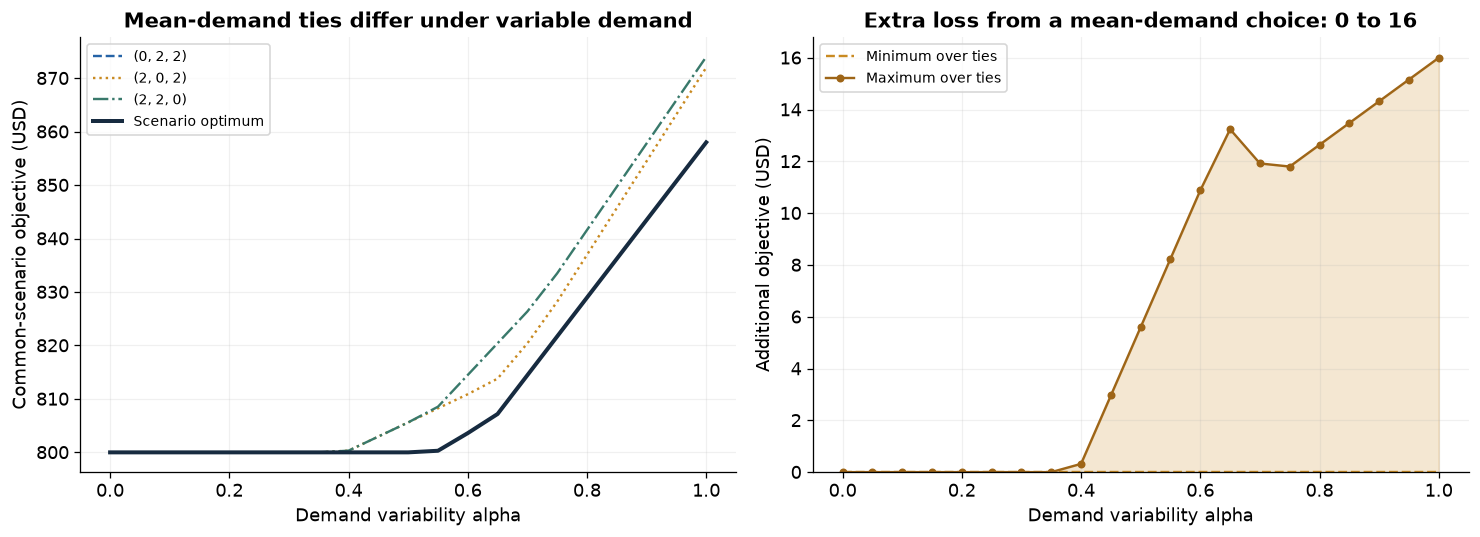

**Result:** At alpha=1, mean-demand allocations have evaluated objectives **858, 872, and 874**. The scenario optimum is **858**, giving extra losses of **0 to 16**. A saving of 16 is not guaranteed. Shading represents the **performance range across tied allocations**, not a confidence interval. A temporary decrease in extra loss is possible because the costs of both methods change; their **difference** need not increase monotonically with variability. This is a comparison under the specified scenarios, not an out-of-sample evaluation.

alpha,q,cost,gap,service_rate,gain,entry,vehicle,idle,unmet_loss
0.0000,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0000,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0000,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.0500,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(2, 0, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1000,"(2, 2, 0)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000
0.1500,"(0, 2, 2)",800.0000,0.0000,0.3509,340.0000,40.0000,20.0000,0.0000,740.0000


In [20]:
sa_mean_data=deepcopy(sa_BASE);sa_mean_data['p']=sa_mean_p.copy()
sa_mean_answer=sa_solve(sa_mean_data,'mean-demand decision')
sa_comparison=[]
for alpha,a in sa_alpha_results:
    evaluated=[sa_evaluate(a['data'],r['y'],r['q']) for r in sa_mean_answer['optima']]
    for r in evaluated:
        gap=r['cost']-a['cost'];assert gap>=-sa_TOL
        sa_comparison.append(dict(alpha=alpha,q=r['q'],cost=r['cost'],gap=max(0.,gap),
            service_rate=r['service_rate'],gain=r['gain'],entry=r['components'][0],
            vehicle=r['components'][1],idle=r['components'][2],unmet_loss=r['components'][3]))
sa_comparison_df=pd.DataFrame(sa_comparison)
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for i,(plot_q,group) in enumerate(sa_comparison_df.groupby('q',sort=True)):
    axes[0].plot(group.alpha,group.cost,label=f'{plot_q}',color=CITY_COLORS[i],
                 linestyle=['--',':','-.'][i])
xx=[v for v,a in sa_alpha_results]; opt=[a['cost'] for v,a in sa_alpha_results]
axes[0].plot(xx,opt,color='#172B40',linewidth=2.5,label=sa_L('Scenario optimum','Scenario optimum'))
axes[0].set_ylabel(sa_L('Common-scenario objective (USD)','Common-scenario objective (USD)'))
axes[0].set_title(sa_L('Mean-demand ties perform differently under variable demand',
                   'Mean-demand ties differ under variable demand'))
axes[0].legend(fontsize=9)
bounds=sa_comparison_df.groupby('alpha')['gap'].agg(['min','max'])
axes[1].fill_between(bounds.index,bounds['min'],bounds['max'],color='#C98A21',alpha=.2)
axes[1].plot(bounds.index,bounds['min'],color='#C98A21',linestyle='--',label=sa_L('Minimum over tied solutions','Minimum over ties'))
axes[1].plot(bounds.index,bounds['max'],color='#9E6517',marker='o',markersize=4,label=sa_L('Maximum over tied solutions','Maximum over ties'))
axes[1].set_ylim(bottom=0);axes[1].set_ylabel(sa_L('Additional objective (USD)','Additional objective (USD)'))
axes[1].set_title(sa_L('Extra loss from mean-demand decisions: 0 to 16', 'Extra loss from a mean-demand choice: 0 to 16'))
axes[1].legend(fontsize=9)
for ax in axes:ax.set_xlabel(sa_L('Demand variability multiplier alpha','Demand variability alpha'));ax.grid(alpha=.18)
fig.tight_layout();sa_showfig(fig,'11_mean_comparison')
assert np.isclose(bounds.loc[1.,'min'],0) and np.isclose(bounds.loc[1.,'max'],16)
sa_note('**Result:** At alpha=1, mean-demand allocations have evaluated objectives **858, 872, and 874**. '
     'The scenario optimum is **858**, giving extra losses of **0 to 16**. '
     'A saving of 16 is not guaranteed. Shading represents the **performance range across tied allocations**, not a confidence interval. '
     'A temporary decrease in extra loss is possible because the costs of both methods '
     'change; their **difference** need not increase monotonically with variability. '
     'This is a comparison under the specified scenarios, not an out-of-sample evaluation.')
sa_detail('All mean-demand allocations: service rate, costs, and improvement',sa_comparison_df)

## 5. Additional parameter comparisons
Evaluate eight parameters at three levels each (24 settings). These comparisons supplement the finer sweeps above. Lines connect the three evaluated points; they do not establish behavior between settings.

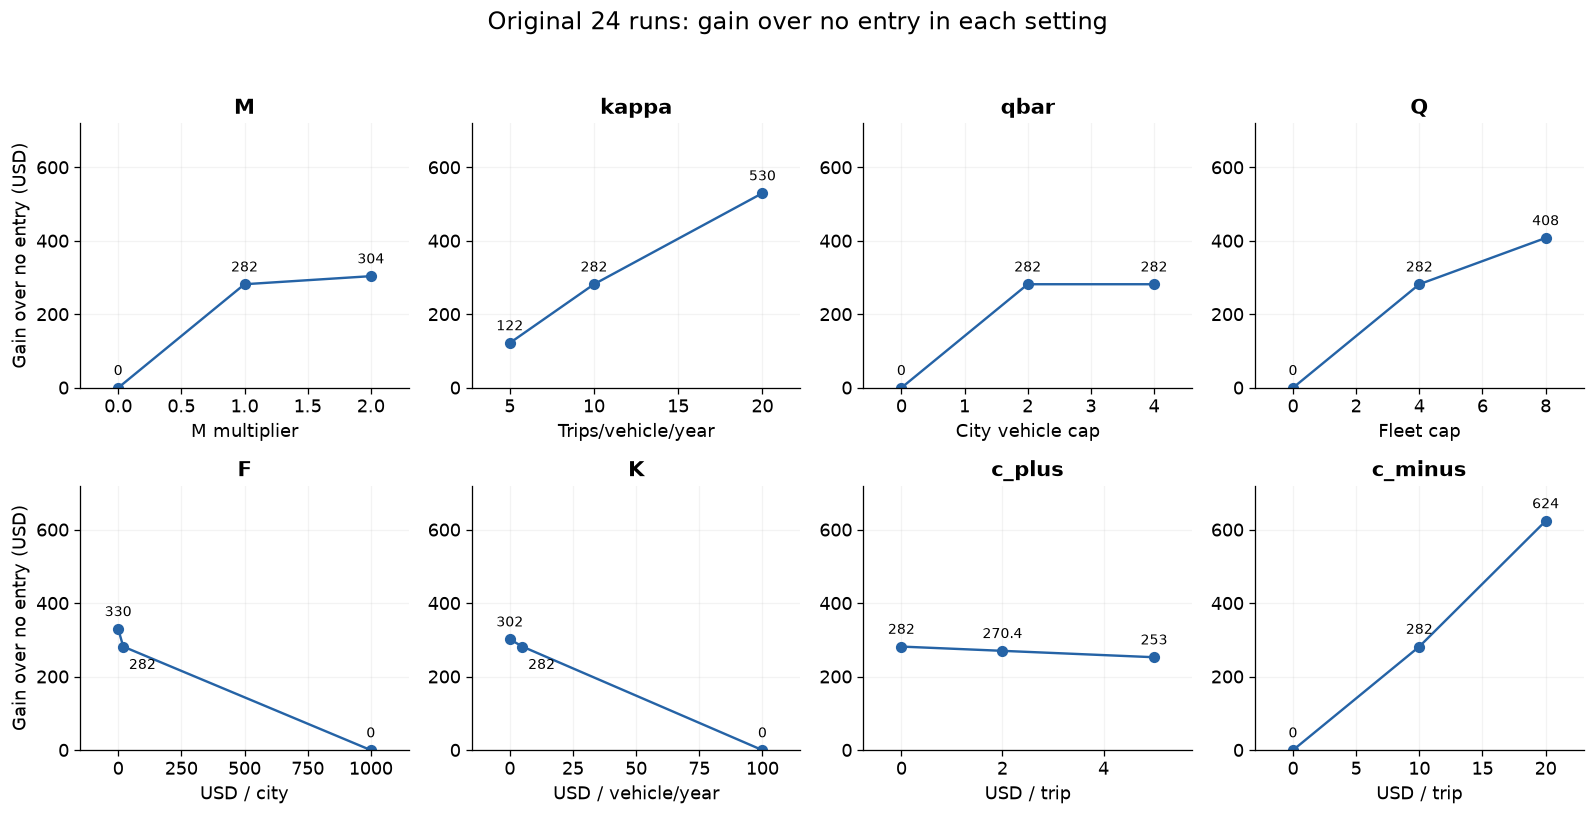

input_value,representative,y,q,optimal_count,service_rate,served_demand,unmet_demand,unused_capacity,entry_cost,vehicle_cost,idle_penalty,unmet_loss,objective,no_entry_baseline,improvement,parameter
0,True,"(0, 0, 0)","(0, 0, 0)",1,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,M
1,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,M
2,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,36.4000,191.6000,3.6000,40.0000,20.0000,0.0000,"1,916.0000","1,976.0000","2,280.0000",304.0000,M
5,True,"(0, 1, 1)","(0, 2, 2)",1,0.1596,18.2000,95.8000,1.8000,40.0000,20.0000,0.0000,958.0000,"1,018.0000","1,140.0000",122.0000,kappa
10,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,kappa
20,True,"(1, 1, 1)","(1, 1, 2)",1,0.5351,61.0000,53.0000,19.0000,60.0000,20.0000,0.0000,530.0000,610.0000,"1,140.0000",530.0000,kappa
0,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000,qbar
2,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,qbar
4,True,"(0, 1, 1)","(0, 2, 2)",1,0.3000,34.2000,79.8000,5.8000,40.0000,20.0000,0.0000,798.0000,858.0000,"1,140.0000",282.0000,qbar
0,True,"(0, 0, 0)","(0, 0, 0)",1,0.0000,0.0000,114.0000,0.0000,0.0000,0.0000,0.0000,"1,140.0000","1,140.0000","1,140.0000",0.0000,Q


**Interpretation:** Doubling M raises the objective but increases improvement over no entry from 282 to 304. Increasing the city limit from 2 to 4 provides no improvement; K=100 gives no entry. At c_plus=0, 2, and 5 the allocation is unchanged, but idle costs reduce improvement. Changing c_minus changes the valuation of unmet trips, so objectives across different coefficients are not direct service-performance rankings. At M=0 the service rate is undefined (NaN), not 0%.

In [21]:
sa_original_levels={
 'M':[(0,np.zeros(3)),(1,sa_BASE['M']),(2,sa_BASE['M']*2)],
 'kappa':[(5,np.full(3,5.)),(10,np.full(3,10.)),(20,np.full(3,20.))],
 'qbar':[(0,np.zeros(3,dtype=int)),(2,np.full(3,2)),(4,np.full(3,4))],
 'Q':[(0,0),(4,4),(8,8)],
 'F':[(0,np.zeros(3)),(20,np.full(3,20.)),(1000,np.full(3,1000.))],
 'K':[(0,np.zeros(3)),(5,np.full(3,5.)),(100,np.full(3,100.))],
 'c_plus':[(0,np.zeros(3)),(2,np.full(3,2.)),(5,np.full(3,5.))],
 'c_minus':[(0,np.zeros(3)),(10,np.full(3,10.)),(20,np.full(3,20.))]}
sa_original_expected={'M':[0,858,1976],'kappa':[1018,858,610],'qbar':[1140,858,858],
                   'Q':[1140,858,732],'F':[810,858,1140],'K':[838,858,1140],
                   'c_plus':[858,869.6,887],'c_minus':[0,858,1656]}
sa_original_results={}
for key,levels in sa_original_levels.items():
    results=[]
    for (value,new),expected in zip(levels,sa_original_expected[key]):
        data=deepcopy(sa_BASE);data[key]=deepcopy(new)
        answer=sa_solve(data,f'original {key}={value}')
        assert abs(answer['cost']-expected)<sa_TOL
        results.append((value,answer))
    sa_original_results[key]=results
fig,axes=plt.subplots(2,4,figsize=(14,7.2))
original_xlabel={'M':sa_L('M multiplier','M multiplier'),'kappa':sa_L('trips/vehicle/year','Trips/vehicle/year'),
                 'qbar':sa_L('Vehicles per city','City vehicle cap'),'Q':sa_L('Total vehicles','Fleet cap'),
                 'F':'USD / city','K':'USD / vehicle/year','c_plus':'USD / trip','c_minus':'USD / trip'}
for ax,(key,results) in zip(axes.flat,sa_original_results.items()):
    values=[x for x,a in results]; reps=[a['rep'] for x,a in results]
    ax.plot(values,[r['gain'] for r in reps],marker='o',color='#2563A6')
    ax.set_title(key);ax.set_xlabel(original_xlabel[key])
    ax.set_ylim(0,720);ax.grid(alpha=.15)
    for i,(x,r) in enumerate(zip(values,reps)):
        offset=(0,8)
        if key in ['F','K'] and i==1: offset=(12,-14)
        ax.annotate(f"{r['gain']:g}",(x,r['gain']),xytext=offset,textcoords='offset points',ha='center',fontsize=9)
    ax.margins(x=.15)
for ax in axes[:,0]:ax.set_ylabel(sa_L('Improvement over no entry (USD)','Gain over no entry (USD)'))
fig.suptitle(sa_L('24 parameter settings: improvement over no entry', 'Original 24 runs: gain over no entry in each setting'),fontsize=15)
fig.tight_layout(rect=[0,0,1,.95]);sa_showfig(fig,'12_original_sweeps')
sa_original_table=pd.concat([sa_full_rows(r).assign(parameter=k) for k,r in sa_original_results.items()],ignore_index=True)
sa_detail('All 24 parameter settings and optimal allocations',sa_original_table)
sa_note('**Interpretation:** Doubling M raises the objective but increases improvement over no entry from 282 to 304. '
     'Increasing the city limit from 2 to 4 provides no improvement; K=100 gives no entry. '
     'At c_plus=0, 2, and 5 the allocation is unchanged, but idle costs reduce improvement. '
     'Changing c_minus changes the valuation of unmet trips, so objectives across different coefficients '
     'are not direct service-performance rankings. At M=0 the service rate is undefined (NaN), not 0%.')

## 6. Findings
1. **Implementation:** q=(0,2,2), objective 858, agrees with independent exhaustive enumeration.
2. **Entry economics:** The third-city service value of 8 is below its entry cost of 20.
3. **Fleet limits:** Beyond Q=6, city limits prevent further improvement.
4. **Productivity:** Increasing kappa from 10 to 20 favors a three-city allocation.
5. **Uncertainty:** Allocations tied under mean demand can perform differently under variable demand.

These results describe the specified synthetic instance and do not estimate an actual market's optimal fleet.


In [22]:
assert all(all(run['checks'].values()) for run in sa_SOLVE_LOG)
assert all(run['gap']<=sa_TOL for run in sa_SOLVE_LOG)
assert len(sa_original_results)==8 and sum(map(len,sa_original_results.values()))==24
sa_cards([('Optimization and exhaustive verification',f'{len(sa_SOLVE_LOG)} passed'),
       ('Expected property check','E1~E8 PASS'),('Sensitivity reference checks','24 / 24 PASS')])
sa_note(f"**Environment:** Python {sys.version.split()[0]}, NumPy {np.__version__}, "
     f"SciPy {scipy.__version__}, pandas {pd.__version__}, Matplotlib {matplotlib.__version__}.\n\n"
     'No random draws are used. The representative selection rule is fixed, and all optimal solutions are retained. '
     'Validation logs are in `SOLVE_LOG`; detailed results are in `experiments`, `original_results`, '
     'and `comparison_df`.')

**Environment:** Python 3.12.14, NumPy 2.5.3, SciPy 1.18.1, pandas 3.0.6, Matplotlib 3.11.2.

No random draws are used. The representative selection rule is fixed, and all optimal solutions are retained. Validation logs are in `SOLVE_LOG`; detailed results are in `experiments`, `original_results`, and `comparison_df`.

## Function reference
- `sa_validate`: input dimensions, bounds, and integer conditions.
- `sa_evaluate`: service, costs, and improvement for a fixed allocation.
- `sa_enumerate_decisions`: exhaustive evaluation of feasible (y,q) pairs for small instances.
- `sa_solve`: MILP solution with exhaustive and feasibility checks.
- `sa_check_expected_result`: expected properties for E1-E8.
- `sa_run_sweep`: one-parameter-at-a-time optimization.
- `sa_plot_sweep`: allocation, service rate, costs, and improvement plots.

Solver interface: [SciPy milp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).
